# G1 | Tabular: Dự đoán giá ô tô cũ ở TP.HCM và Hà Nội (Chợ Tốt)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/minhtho1503/data-analysis-visualization-g1/blob/main/projects/tabular/tabular.ipynb)

| | |
|---|---|
| Môn học | Nền tảng lập trình cho phân tích và trực quan dữ liệu (CO5177), học kỳ 261 (2026-2027) |
| Trường | Trường Đại học Bách Khoa - ĐHQG-HCM |
| Giảng viên | TS. Lê Thành Sách |
| Nhóm | G1 |
| Người phụ trách | Phan Thị Minh Thơ (2470112) |
| Dữ liệu | Tin rao bán ô tô trên Chợ Tốt ở TP.HCM và Hà Nội, nhóm tự thu thập ngày 20/11/2026 (12 237 tin, 30 cột) |
| Bài toán | Hồi quy có giám sát: dự đoán giá rao bán (VND) của một chiếc ô tô đã qua sử dụng từ thông tin trong tin đăng |

## Bối cảnh dữ liệu

Giá một chiếc ô tô cũ phụ thuộc vào nhiều thứ cùng lúc: dòng xe, đời xe, số km, phiên bản, nơi bán. Người mua khó biết
một mức giá rao là hợp lý hay không, còn người bán khó biết nên rao bao nhiêu. Notebook này xây dựng mô hình ước lượng
giá rao bán của một chiếc ô tô đã qua sử dụng từ các thông tin có trong tin đăng, đồng thời trả lời các câu hỏi:

* Tin rao tự thu thập thiếu những gì, thiếu vì sao, và nên điền như thế nào để có cơ sở?
* Mỗi năm tuổi, một chiếc xe mất bao nhiêu phần trăm giá, và hãng nào giữ giá tốt nhất?
* Khi cùng dòng xe và cùng đời, số km, thành phố và xuất xứ ảnh hưởng tới giá đến đâu?

**Mục lục**

1. Thiết lập và tải dữ liệu
2. Mô tả dữ liệu
3. Kiểm tra chất lượng dữ liệu
4. Phân tích khám phá (EDA)
5. Tiền xử lý dữ liệu
6. Xây dựng mô hình
7. Đánh giá trên tập test
8. Dự đoán giá một chiếc xe
9. Kết luận

> **Cách chạy:** trên Google Colab chọn *Runtime > Run all* (không cần GPU). Notebook tự tải dữ liệu từ repo GitHub của
> nhóm nếu chưa có file trong thư mục `data/`.

## 1. Thiết lập và tải dữ liệu

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import sklearn
from IPython.display import display, Markdown

from sklearn.base import BaseEstimator, TransformerMixin, RegressorMixin
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score

print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

Python 3.12.13 | pandas 2.2.2 | scikit-learn 1.6.1


In [2]:
SEED = 261
np.random.seed(SEED)

DATA_URL = "https://raw.githubusercontent.com/minhtho1503/data-analysis-visualization-g1/main/projects/tabular/data/chotot_oto.csv"
TARGET = "price_vnd"
CRAWL_YEAR = 2026

IN_COLAB = "google.colab" in sys.modules
HERE = Path("/content") if IN_COLAB else Path.cwd()
if (HERE / "projects" / "tabular").is_dir():
    HERE = HERE / "projects" / "tabular"
DATA_DIR, FIG_DIR, RESULTS_DIR = HERE / "data", HERE / "figures", HERE / "results"
for d in (DATA_DIR, FIG_DIR, RESULTS_DIR):
    d.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

In [3]:
MAIN, ACCENT, GREY = "#2B4C7E", "#E07A2F", "#9AA5B1"
TEXT, MUTED, TRACK = "#1F2937", "#6B7280", "#E9EDF3"
CITY_COLORS = {"TP.HCM": MAIN, "Hà Nội": ACCENT}

sns.set_theme(style="white", palette=[MAIN, ACCENT, "#2A9D8F", "#8E6BB8", GREY])
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Liberation Sans", "DejaVu Sans"],
    "figure.dpi": 110, "text.color": TEXT, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": TEXT,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlesize": 13, "axes.titlepad": 12,
    "axes.edgecolor": "#D0D5DD", "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "grid.color": "#EEF1F5", "axes.axisbelow": True, "legend.frameon": False,
})


def hbars(ax, labels, values, colors=MAIN, notes=None, xmax=None, ref=None, lw=10):
    """Thanh ngang bo tròn trên nền xám, xếp từ trên xuống theo thứ tự của labels.
    notes: mỗi thanh một cặp (số in đậm, ghi chú xám, có thể None) in bên phải; ref: đường đứt tại giá trị này."""
    values = np.asarray(values, dtype=float)
    y = np.arange(len(values))[::-1]
    xmax = xmax or values.max()
    ax.hlines(y, 0, xmax, color=TRACK, lw=lw, capstyle="round", clip_on=False)
    ax.hlines(y, 0, values, color=colors, lw=lw, capstyle="round", clip_on=False)
    if ref is not None:
        ax.axvline(ref, color=MUTED, ls="--", lw=1)
    ax.set(xlim=(0, xmax), ylim=(-0.7, len(values) - 0.3))
    ax.set_yticks(y, labels)
    ax.tick_params(axis="y", length=0, pad=12)
    ax.tick_params(axis="x", bottom=False, labelbottom=False)
    ax.grid(False)
    for side in ax.spines.values():
        side.set_visible(False)
    at = ax.get_yaxis_transform()
    for yi, (bold, extra) in zip(y, notes or []):
        if extra is None:
            ax.annotate(bold, (1, yi), xycoords=at, xytext=(12, 0), textcoords="offset points",
                        ha="left", va="center", fontweight="bold")
        else:
            ax.annotate(bold, (1, yi), xycoords=at, xytext=(58, 0), textcoords="offset points",
                        ha="right", va="center", fontweight="bold")
            ax.annotate(extra, (1, yi), xycoords=at, xytext=(66, 0), textcoords="offset points",
                        ha="left", va="center", color=MUTED)


FIG_NO = 0


def show_fig(fig, name, caption):
    global FIG_NO
    FIG_NO += 1
    axes = fig.get_axes()
    if len(axes) == 1 and axes[0].get_title(loc="left"):
        fig.suptitle(axes[0].get_title(loc="left"), x=0.01, ha="left", fontweight="bold", fontsize=13)
        axes[0].set_title("", loc="left")
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"fig{FIG_NO:02d}_{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    display(Markdown(f"**Hình {FIG_NO}.** {caption}"))


def num(x):
    return f"{x:,.0f}".replace(",", " ")


def pct(x, d=1):
    return f"{100 * x:.{d}f}%"


def trieu(x, _pos=None):
    return f"{x / 1e6:,.0f}".replace(",", " ")

In [4]:
path = DATA_DIR / "chotot_oto.csv"
if not path.exists():
    pd.read_csv(DATA_URL).to_csv(path, index=False)
raw = pd.read_csv(path, parse_dates=["posted_at", "orig_posted_at", "crawled_at"])
print("raw.shape =", raw.shape)
raw.head()

raw.shape = (12237, 30)


,list_id,city,district,posted_at,orig_posted_at,subject,brand,model,mfg_year,body_type,seats,gearbox,fuel,origin,color,condition,mileage_km,owners,has_registration,has_accessories,price_vnd,is_price_not_valid,seller_is_shop,seller_live_ads,seller_sold_ads,seller_avg_rating,seller_total_rating,number_of_images,has_video,crawled_at
0,135839881,TP.HCM,Thành phố Thủ Đức,2026-11-20 15:57:54,2026-11-14 15:54:46,VinFast Fadil 2020 Base 64.000 km Xám,VinFast,Fadil,2019,Hatchback,Khác,Tự động,Xăng,Việt Nam,Xám,Đã sử dụng,64000.0,NaN,Có,NaN,229000000,NaN,False,1,NaN,NaN,NaN,8,False,2026-11-20 15:58:41
1,135950447,TP.HCM,Quận 5,2026-11-20 15:57:52,2026-11-20 15:57:49,MERCEDES-BENZ E280 2009 ĐEN TỰ ĐỘNG,Mercedes Benz,E Class,2009,NaN,NaN,Tự động,Xăng,NaN,Đen,Đã sử dụng,100000.0,NaN,Có,NaN,189000000,NaN,True,6,NaN,NaN,NaN,16,False,2026-11-20 15:58:41
2,135938099,TP.HCM,Thành phố Thủ Đức,2026-11-20 15:57:03,2026-11-19 21:52:52,Xe Hyundai Tucson 2.0 AT Tiêu chuẩn 2021,Hyundai,Tucson,2021,SUV / Cross over,5,Tự động,Xăng,NaN,NaN,Đã sử dụng,53000.0,NaN,NaN,NaN,545000000,NaN,True,4,5.0,NaN,NaN,5,False,2026-11-20 15:58:41
3,135475153,TP.HCM,Thành phố Thủ Đức,2026-11-20 15:56:58,2026-10-26 15:08:12,Mazda 3 2020 30.000km Trắng,Mazda,3,2020,NaN,NaN,Tự động,Xăng,NaN,Trắng,Đã sử dụng,30000.0,NaN,NaN,NaN,425000000,NaN,True,4,NaN,4.2,12.0,8,False,2026-11-20 15:58:41
4,133623692,TP.HCM,Quận Tân Phú,2026-11-20 15:56:18,2026-09-25 15:27:15,XC90 B6 Ultimate 2023 Platinum Gray Thụy Điển,Volvo,XC90,2022,SUV / Cross over,7,Tự động,Xăng,Nước khác,Xám,Đã sử dụng,58000.0,NaN,NaN,NaN,2370000000,NaN,True,2,NaN,2.0,1.0,17,False,2026-11-20 15:58:41


## 2. Mô tả dữ liệu

### 2.1 Tổng quan

- **Nguồn:** chuyên mục *Ô tô* của Chợ Tốt (chotot.com), trang rao vặt lớn ở Việt Nam. Nhóm tự thu thập bằng script
  [`crawl_chotot_oto.py`](crawl_chotot_oto.py) qua API công khai mà trang web dùng để hiển thị danh sách tin
  (`gateway.chotot.com/v1/public/ad-listing`, chuyên mục `cg=2010`), không cần đăng nhập, khoảng 1 request mỗi giây.
- **Phạm vi:** toàn bộ tin đang hiển thị ở TP.HCM và Hà Nội lúc thu thập (chiều 20/11/2026), gồm cả xe mới và xe đã qua
  sử dụng. Tin cũ nhất được đăng ngày 21/09/2026.
- **Nhãn chữ:** API trả kiểu dáng, số ghế, xuất xứ, màu, hộp số, nhiên liệu... dưới dạng mã số. Script tra nhãn của mỗi
  mã bằng API chi tiết của một tin có mã đó.
- **Ẩn danh:** file CSV không chứa tên người bán, ID tài khoản, ảnh, phần mô tả tự do, địa chỉ, tọa độ và biển số. Số
  điện thoại và biển số xuất hiện trong tiêu đề được che. Về người bán, chỉ giữ các con số tổng hợp (số tin đang rao,
  số tin đã bán, điểm đánh giá).
- **Nhãn của bài toán:** `price_vnd` là **giá rao bán** do người bán tự đặt, không phải giá giao dịch.

In [5]:
by_city = raw.groupby("city").agg(so_tin=("list_id", "size"), xe_da_dung=("condition", lambda s: (s == "Đã sử dụng").sum()),
                                  so_quan_huyen=("district", "nunique"), so_dong_xe=("model", "nunique"),
                                  tin_som_nhat=("posted_at", "min"), tin_moi_nhat=("posted_at", "max"))
by_city

,so_tin,xe_da_dung,so_quan_huyen,so_dong_xe,tin_som_nhat,tin_moi_nhat
city,,,,,,
Hà Nội,3397,3111,30,288,2026-09-21 16:13:54,2026-11-20 16:00:32
TP.HCM,8840,7575,22,389,2026-09-21 16:04:27,2026-11-20 15:57:54


### 2.2 Cấu trúc dữ liệu

Mỗi dòng là một tin rao bán một chiếc xe.

| Nhóm | Cột | Ý nghĩa |
|---|---|---|
| Tin đăng | `list_id`, `subject`, `posted_at`, `orig_posted_at`, `crawled_at`, `number_of_images`, `has_video`, `is_price_not_valid` | mã tin, tiêu đề, ngày đăng (lần gần nhất / lần đầu), ngày thu thập, số ảnh, có video, cờ "giá không hợp lệ" của Chợ Tốt |
| Nơi bán | `city`, `district` | thành phố, quận/huyện |
| Chiếc xe | `brand`, `model`, `mfg_year`, `body_type`, `seats`, `gearbox`, `fuel`, `origin`, `color`, `condition`, `mileage_km` | hãng, dòng xe, năm sản xuất, kiểu dáng, số ghế, hộp số, nhiên liệu, xuất xứ, màu, tình trạng (mới / đã sử dụng), số km đã đi |
| Giấy tờ | `owners`, `has_registration`, `has_accessories` | số đời chủ, còn đăng kiểm, có kèm phụ kiện |
| Người bán | `seller_is_shop`, `seller_live_ads`, `seller_sold_ads`, `seller_avg_rating`, `seller_total_rating` | là salon hay cá nhân, số tin đang rao, số tin đã bán, điểm và số lượt đánh giá |
| **Target** | `price_vnd` | giá rao bán (VND) |

In [6]:
def overview(df):
    return pd.DataFrame({"dtype": df.dtypes.astype(str), "n_missing": df.isna().sum(),
                         "pct_missing": df.isna().mean().mul(100).round(1), "n_unique": df.nunique(),
                         "ví dụ": df.iloc[0]})

overview(raw)

,dtype,n_missing,pct_missing,n_unique,ví dụ
list_id,int64,0,0.0,12237,135839881
city,object,0,0.0,2,TP.HCM
district,object,0,0.0,52,Thành phố Thủ Đức
posted_at,datetime64[ns],0,0.0,11784,2026-11-20 15:57:54
orig_posted_at,datetime64[ns],2049,16.7,10142,2026-11-14 15:54:46
subject,object,0,0.0,12025,VinFast Fadil 2020 Base 64.000 km Xám
brand,object,0,0.0,69,VinFast
model,object,0,0.0,435,Fadil
mfg_year,int64,0,0.0,42,2019
body_type,object,3034,24.8,9,Hatchback


### 2.3 Phân phối các cột

Các cột phân loại chính và các cột số chính trên toàn bộ bảng thô.

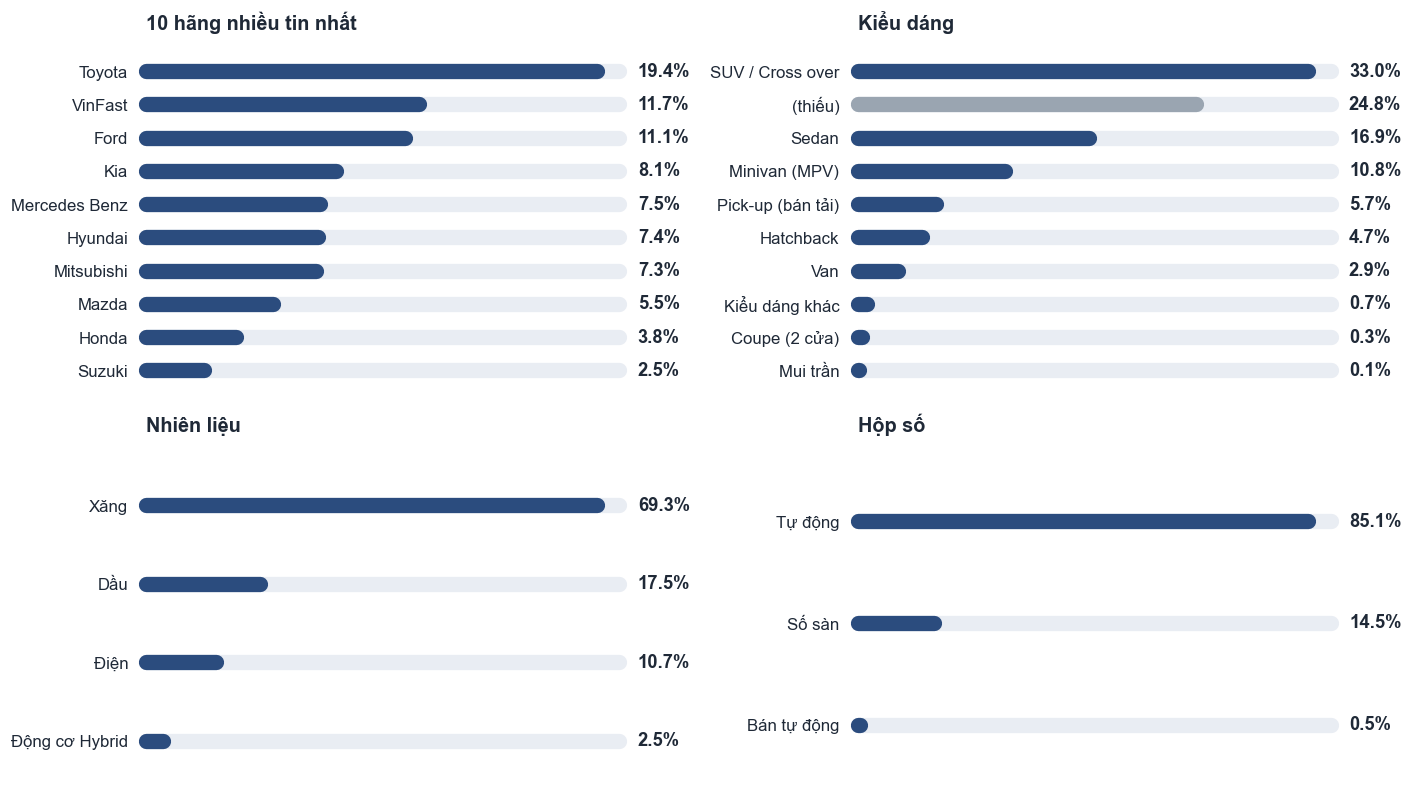

**Hình 1.** Ba hãng nhiều tin nhất là Toyota, VinFast, Ford, chiếm 42% số tin. SUV chiếm phần lớn nhất trong các kiểu dáng; 25% tin không ghi kiểu dáng (thanh xám). 11% số tin là xe điện và 85% là xe số tự động.

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7.5))
panels = [("brand", "10 hãng nhiều tin nhất", 10), ("body_type", "Kiểu dáng", None),
          ("fuel", "Nhiên liệu", None), ("gearbox", "Hộp số", None)]
for ax, (col, title, top) in zip(axes.flat, panels):
    share = raw[col].value_counts(normalize=True, dropna=False)
    share.index = share.index.fillna("(thiếu)")
    share = share.head(top) if top else share
    hbars(ax, share.index, share.values, colors=[GREY if i == "(thiếu)" else MAIN for i in share.index],
          xmax=share.max() * 1.05, notes=[(pct(v), None) for v in share])
    ax.set_title(title)
top_brands = raw["brand"].value_counts(normalize=True)
show_fig(fig, "categorical",
    f"Ba hãng nhiều tin nhất là {', '.join(top_brands.index[:3])}, chiếm {pct(top_brands.iloc[:3].sum(), 0)} số tin. "
    f"SUV chiếm phần lớn nhất trong các kiểu dáng; {pct(raw['body_type'].isna().mean(), 0)} tin không ghi kiểu dáng "
    f"(thanh xám). {pct((raw['fuel'] == 'Điện').mean(), 0)} số tin là xe điện và {pct((raw['gearbox'] == 'Tự động').mean(), 0)} "
    f"là xe số tự động.")

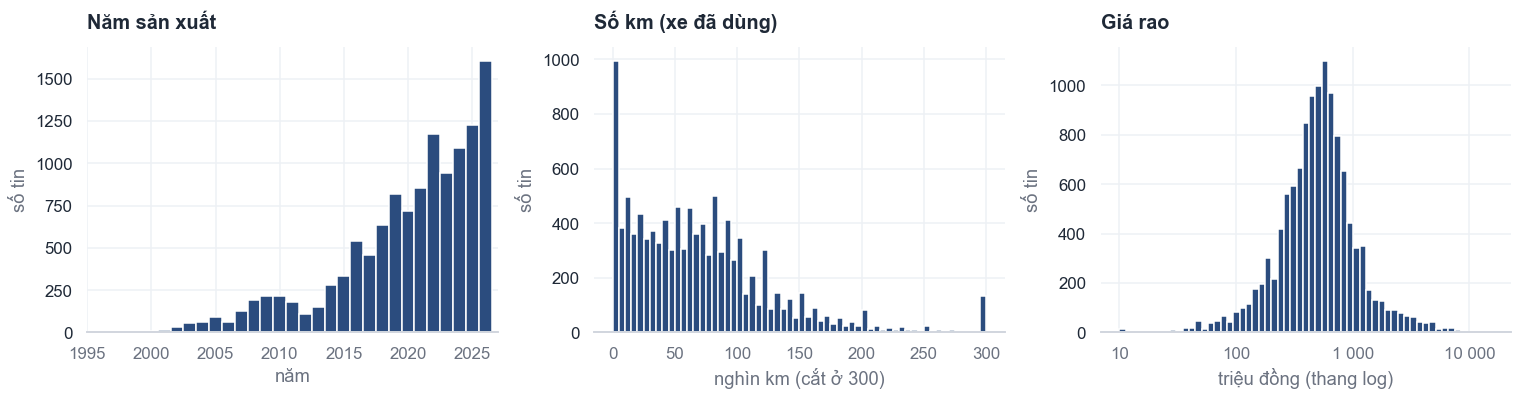

**Hình 2.** Năm sản xuất tập trung ở các đời gần đây (median 2021), có một cột cao ở 2026 vì tin xe mới. Số km của xe đã dùng có đỉnh nhọn tại các số tròn: 31% tin ghi bội số của 10 000 km, dấu hiệu người bán ước lượng. Giá trải từ vài chục triệu tới hơn 10 tỷ, nên trục giá phải dùng thang log.

In [8]:
used_raw = raw[raw["condition"] == "Đã sử dụng"]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].hist(raw["mfg_year"], bins=np.arange(1985, CRAWL_YEAR + 2) - 0.5, color=MAIN)
axes[0].set(title="Năm sản xuất", xlabel="năm", ylabel="số tin", xlim=(1995, CRAWL_YEAR + 1))
axes[1].hist(used_raw["mileage_km"].clip(upper=300_000) / 1000, bins=60, color=MAIN)
axes[1].set(title="Số km (xe đã dùng)", xlabel="nghìn km (cắt ở 300)", ylabel="số tin")
axes[2].hist(raw[TARGET].clip(lower=1e7) / 1e6, bins=np.logspace(1, 4.2, 60), color=MAIN)
axes[2].set(xscale="log", title="Giá rao", xlabel="triệu đồng (thang log)", ylabel="số tin")
axes[2].xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", " ")))
round_km = used_raw["mileage_km"].dropna()
show_fig(fig, "numeric",
    f"Năm sản xuất tập trung ở các đời gần đây (median {raw['mfg_year'].median():.0f}), có một cột cao ở {CRAWL_YEAR} vì "
    f"tin xe mới. Số km của xe đã dùng có đỉnh nhọn tại các số tròn: {pct(round_km.mod(10_000).eq(0).mean(), 0)} tin ghi "
    f"bội số của 10 000 km, dấu hiệu người bán ước lượng. Giá trải từ vài chục triệu tới hơn 10 tỷ, nên trục giá "
    f"phải dùng thang log.")

**Bài toán và hướng tiếp cận**

Đây là bài toán **hồi quy**: mô hình nhận thông tin của một tin rao (dòng xe, năm sản xuất, số km, kiểu dáng, nơi bán,
người bán...) và dự đoán giá rao bán. Các bước chính:

1. Kiểm tra chất lượng dữ liệu, đặc biệt là giá trị thiếu: thiếu ở đâu, thiếu vì sao, thiếu có liên quan tới giá không.
   Sửa hoặc bỏ tin sai bằng luật cố định, giới hạn bài toán vào xe đã qua sử dụng thuộc các dòng phổ biến, rồi chia
   train / validation / test (mục 3).
2. Phân tích khám phá trên train để tìm các yếu tố quyết định giá (mục 4).
3. Tiền xử lý: tạo feature, điền giá trị thiếu theo dòng xe, mã hóa, chuẩn hóa; mọi thống kê chỉ học từ train (mục 5).
4. So sánh baseline và các mô hình hồi quy bằng cross-validation 5 fold trên train và trên validation; kiểm tra ảnh
   hưởng của cách điền giá trị thiếu tới mô hình (mục 6).
5. Đánh giá một lần trên test, phân tích lỗi và dự đoán giá một chiếc xe (mục 7, 8).

## 3. Kiểm tra chất lượng dữ liệu

Các kiểm tra ở mục này chạy trên toàn bộ bảng thô. Luật sửa lỗi ở đây là luật cố định theo từng dòng, không học con số
nào từ dữ liệu, nên áp dụng trước khi chia tập không gây rò rỉ.

### 3.1 Giá trị thiếu: thiếu vì không áp dụng

Tỉ lệ thiếu của từng cột, tách theo tình trạng xe. Hai cột metadata không đưa vào hình: `orig_posted_at` chỉ có ở tin
đã được đăng lại, còn `is_price_not_valid` là cờ nội bộ của Chợ Tốt (mục 3.4).

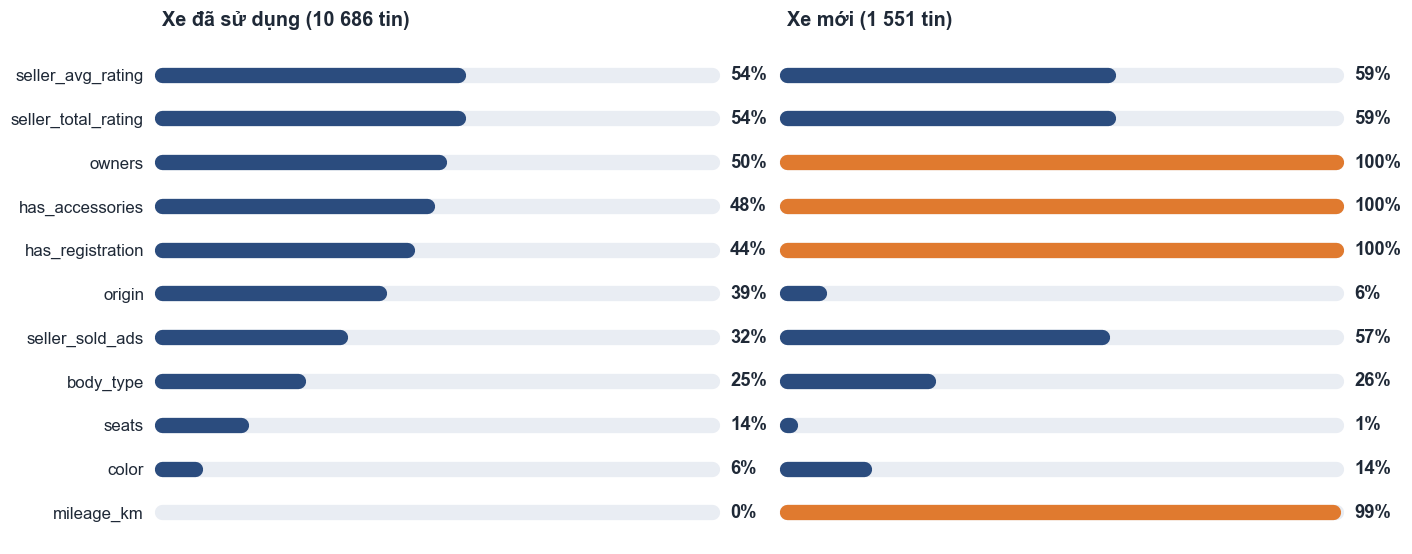

**Hình 3.** Ở tin xe mới, `owners`, `has_accessories`, `has_registration`, `mileage_km` gần như luôn trống (màu cam): form đăng xe mới không hỏi các mục này, và với xe mới chúng cũng không có nghĩa. Đây là thiếu *không áp dụng*, không cần điền. Ở xe đã dùng, `mileage_km` đầy đủ, còn 10 cột thiếu từ 1% trở lên, nhiều nhất là `seller_avg_rating` (54%).

In [9]:
miss_cols = raw.columns[raw.isna().any()].drop(["orig_posted_at", "is_price_not_valid"])
miss_by_cond = raw.groupby("condition")[list(miss_cols)].apply(lambda g: g.isna().mean()).T
miss_by_cond = miss_by_cond.sort_values("Đã sử dụng", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), sharey=True)
for ax, cond in zip(axes, ["Đã sử dụng", "Mới"]):
    vals = miss_by_cond[cond]
    hbars(ax, vals.index, vals.values, colors=[ACCENT if v > 0.9 else MAIN for v in vals], xmax=1,
          notes=[(pct(v, 0), None) for v in vals])
    ax.set_title(f"Xe {cond.lower()} ({num((raw['condition'] == cond).sum())} tin)")
na_new = miss_by_cond.index[miss_by_cond["Mới"] > 0.9]
show_fig(fig, "missing_by_condition",
    f"Ở tin xe mới, {', '.join(f'`{c}`' for c in na_new)} gần như luôn trống (màu cam): form đăng xe mới không hỏi các "
    f"mục này, và với xe mới chúng cũng không có nghĩa. Đây là thiếu *không áp dụng*, không cần điền. Ở xe đã dùng, "
    f"`mileage_km` đầy đủ, còn {(miss_by_cond['Đã sử dụng'] >= 0.01).sum()} cột thiếu từ 1% trở lên, nhiều nhất là "
    f"`{miss_by_cond.index[0]}` ({pct(miss_by_cond['Đã sử dụng'].iloc[0], 0)}).")

- **Nhận xét:**
  - Có hai kiểu thiếu khác nhau. Ở **xe mới** (1 551 tin), `mileage_km`, `owners`, `has_registration`,
    `has_accessories` trống gần như 100% vì không áp dụng. Ở **xe đã dùng** (10 686 tin), các ô trống là do người bán
    bỏ qua mục không bắt buộc: `owners` 50%, `has_accessories` 48%, `has_registration` 44%, `origin` 39%, `body_type`
    25%, `seats` 14% (19% nếu tính cả giá trị `Khác`, mục 3.2), `color` 6%. Các cột về người bán trống khi người bán
    chưa có lượt bán hoặc lượt đánh giá nào.
  - Các cột quan trọng nhất (hãng, dòng xe, năm sản xuất, hộp số, nhiên liệu, giá) không thiếu ô nào.
- **Quyết định:** giới hạn bài toán ở xe đã dùng (mục 3.8), nên kiểu thiếu "không áp dụng" không còn. Kiểu thiếu do
  người bán bỏ trống được phân tích tiếp ở mục 3.3 và xử lý ở mục 5.3.

### 3.2 Giá trị thiếu ẩn

Có những ô không trống nhưng thực chất là "không biết": số ghế ghi `Khác`, hoặc xe đã dùng nhiều năm mà khai 0 km.

In [10]:
age_raw = CRAWL_YEAR - used_raw["mfg_year"]
km = used_raw["mileage_km"]
hidden = pd.DataFrame({
    "số tin": [(used_raw["seats"] == "Khác").sum(), km.eq(0).sum(), (km.between(1, 999) & (age_raw >= 2)).sum(),
               (km > 500_000).sum()],
}, index=["seats = 'Khác'", "mileage_km = 0", "mileage_km dưới 1 000 nhưng xe từ 2 năm tuổi", "mileage_km trên 500 000"])
hidden["% xe đã dùng"] = (hidden["số tin"] / len(used_raw) * 100).round(1)
display(hidden)
print("Ví dụ xe khai dưới 1 000 km:")
display(used_raw.loc[km.lt(1000) & (age_raw >= 2), ["subject", "mfg_year", "mileage_km", TARGET]].head(5))
print("Ví dụ xe khai trên 500 000 km:")
display(used_raw.loc[km > 500_000, ["subject", "mfg_year", "mileage_km", TARGET]].head(5))

,số tin,% xe đã dùng
seats = 'Khác',490,4.6
mileage_km = 0,177,1.7
mileage_km dưới 1 000 nhưng xe từ 2 năm tuổi,479,4.5
mileage_km trên 500 000,55,0.5


Ví dụ xe khai dưới 1 000 km:


,subject,mfg_year,mileage_km,price_vnd
12,Mercedes Benz GLC 300 V1 siêu lướt,2023,25.0,2299000000
20,KIA K3 2024 2.0 Premium 4v8 trắng,2024,48.0,538000000
38,Mercedes E200 Đỏ siêu lướt,2023,28.0,1899000000
52,Audi Q5 2016 2.0 Quattro,2016,11.0,539000000
65,Lexus GX 460 2010 Trắng Mỹ,2010,0.0,960000000


Ví dụ xe khai trên 500 000 km:


,subject,mfg_year,mileage_km,price_vnd
419,Toyota Camry 1999 G Bạc,1999,686868.0,80000000
585,Porsche Panamera S úp lên đời Cao đẹp.giao lưu xe,2010,800000.0,675000000
961,Mitsubishi Zinger 2009 Xám 8 chỗ,2009,501890.0,132000000
1244,BMW E46 318i Số tự động Xanh đậm,2003,888888.0,125000000
1678,PEUGEOT 3008 2015 TỰ ĐỘNG ĐEN,2015,999999.0,258000000


- **Nhận xét:**
  - 490 tin xe đã dùng (4.6%) ghi số ghế `Khác`, tức không cho biết số ghế.
  - 177 tin khai 0 km và 479 tin khai dưới 1 000 km dù xe đã từ 2 năm tuổi, ví dụ một chiếc Lexus GX 460 đời 2010
    khai 0 km, một chiếc Audi Q5 đời 2016 khai 11 km. Vài tin "siêu lướt" ghi 25 hay 28 km có lẽ muốn nói 25 000 km.
    Với xe dưới 2 năm tuổi, số km nhỏ có thể là thật nên được giữ.
  - 55 tin khai trên 500 000 km, nhiều con số có dạng lặp như 686 868, 888 888, 999 999.
- **Quyết định:** coi các giá trị này là **thiếu**: `seats = Khác` thành ô trống; số km dưới 1 000 ở xe từ 2 năm tuổi
  hoặc trên 500 000 thành ô trống. Tin vẫn được giữ vì các cột còn lại dùng được; ô trống được điền ở mục 5.3.

### 3.3 Thiếu có ngẫu nhiên không?

Cách điền chỉ có cơ sở nếu biết dữ liệu thiếu theo kiểu nào. Ba kiểm tra trên xe đã dùng:

1. **Các cột có thiếu cùng nhau không?** Tương quan giữa các cờ "bị thiếu" (1 nếu ô trống).
2. **Ai bỏ trống nhiều hơn?** Tỉ lệ thiếu ở salon so với người bán cá nhân.
3. **Tin bị thiếu có rẻ hay đắt hơn không?** Giá của mỗi tin được chia cho giá median của các tin cùng dòng xe và cùng
   năm sản xuất, rồi so median của tỉ số này giữa tin có thiếu và tin đầy đủ. Tỉ số gần 1 nghĩa là việc thiếu không đi
   kèm giá cao hay thấp hơn khi đã biết dòng xe và đời xe.

,% thiếu,% thiếu ở salon,% thiếu ở cá nhân,giá tương đối khi thiếu,giá tương đối khi có
body_type,24.66,21.91,31.95,1.0,1.0
seats,18.97,19.03,18.82,1.0,1.0
origin,39.48,38.48,42.15,1.0,1.0
color,5.91,6.22,5.10,1.0,1.0
owners,50.39,47.58,57.85,1.0,1.0
has_registration,44.48,43.95,45.88,1.0,1.0
has_accessories,48.10,44.96,56.45,1.0,1.0


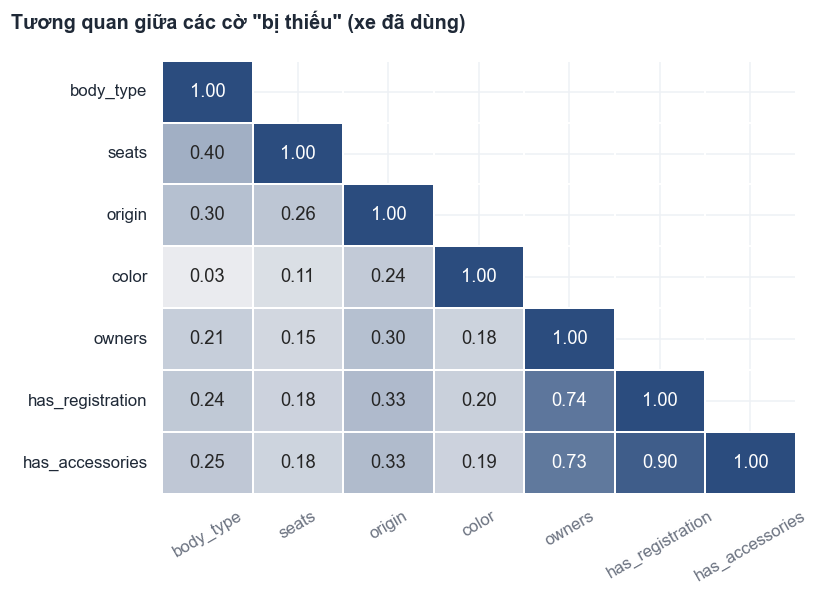

**Hình 4.** Ba cột giấy tờ (`owners`, `has_registration`, `has_accessories`) thiếu cùng nhau (tương quan 0.73 - 0.90): người bán bỏ qua cả nhóm mục này một lúc. `body_type` và `seats` cũng hay thiếu cùng nhau (0.40). Các cặp còn lại tương quan yếu.

In [11]:
SELLER_LEFT_BLANK = ["body_type", "seats", "origin", "color", "owners", "has_registration", "has_accessories"]
used_flags = used_raw.assign(seats=used_raw["seats"].replace("Khác", np.nan))
is_na = used_flags[SELLER_LEFT_BLANK].isna().astype(int)

key = used_flags["brand"] + "|" + used_flags["model"] + "|" + used_flags["mfg_year"].astype(str)
group_size = key.map(key.value_counts())
relative = used_flags[TARGET] / used_flags.groupby(key)[TARGET].transform("median")
comparable = group_size >= 5

miss_test = pd.DataFrame({
    "% thiếu": is_na.mean() * 100,
    "% thiếu ở salon": is_na[used_flags["seller_is_shop"]].mean() * 100,
    "% thiếu ở cá nhân": is_na[~used_flags["seller_is_shop"]].mean() * 100,
    "giá tương đối khi thiếu": [relative[comparable & is_na[c].astype(bool)].median() for c in SELLER_LEFT_BLANK],
    "giá tương đối khi có": [relative[comparable & ~is_na[c].astype(bool)].median() for c in SELLER_LEFT_BLANK],
}).round(2)
display(miss_test)

fig, ax = plt.subplots(figsize=(7.5, 5.5))
corr = is_na.corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap=sns.light_palette(MAIN, as_cmap=True), vmin=0, vmax=1,
            cbar=False, linewidths=1, linecolor="white", ax=ax)
ax.set(title="Tương quan giữa các cờ \"bị thiếu\" (xe đã dùng)")
ax.tick_params(axis="x", rotation=30)
paper = corr.loc[["owners", "has_registration", "has_accessories"], ["owners", "has_registration", "has_accessories"]]
show_fig(fig, "missing_correlation",
    f"Ba cột giấy tờ (`owners`, `has_registration`, `has_accessories`) thiếu cùng nhau (tương quan "
    f"{paper.where(~np.eye(3, dtype=bool)).min().min():.2f} - {paper.where(~np.eye(3, dtype=bool)).max().max():.2f}): "
    f"người bán bỏ qua cả nhóm mục này một lúc. `body_type` và `seats` cũng hay thiếu cùng nhau "
    f"({corr.loc['body_type', 'seats']:.2f}). Các cặp còn lại tương quan yếu.")

- **Nhận xét:**
  - **Thiếu cùng nhau:** ba cột giấy tờ thiếu cùng nhau (tương quan 0.73 - 0.90), nghĩa là người bán bỏ qua cả nhóm
    mục này một lúc chứ không phải từng ô ngẫu nhiên. `body_type` và `seats` cũng hay thiếu cùng nhau (0.40).
  - **Ai bỏ trống:** người bán cá nhân bỏ trống nhiều hơn salon ở `body_type` (32% so với 22%), `owners` (58% so với
    48%) và `has_accessories` (56% so với 45%); ở các cột còn lại, hai nhóm chênh nhau không quá 4 điểm %.
  - **Thiếu và giá:** với cả 7 cột, giá tương đối của tin bị thiếu và của tin đầy đủ đều bằng 1.00. Khi đã biết dòng xe
    và đời xe, việc người bán bỏ trống một mục không cho biết chiếc xe đắt hay rẻ hơn.
- **Kết luận:** việc thiếu phụ thuộc vào người bán và cách họ điền form, tức vào những thứ quan sát được, chứ không
  phụ thuộc vào giá. Vì vậy có thể điền ô thiếu dựa trên các cột khác mà không làm lệch mô hình. Cột nào điền được và
  điền bằng gì được kiểm tra bằng số ở mục 5.3.

### 3.4 Giá không hợp lệ

In [12]:
print("Cờ is_price_not_valid của Chợ Tốt:", raw["is_price_not_valid"].value_counts(dropna=False).to_dict())
price_checks = pd.Series({
    "giá = 0": (raw[TARGET] == 0).sum(),
    "giá dưới 20 triệu": (raw[TARGET] < 20e6).sum(),
    "giá dưới 100 triệu": (raw[TARGET] < 100e6).sum(),
    "giá trên 10 tỷ": (raw[TARGET] > 10e9).sum(),
}, name="số tin")
display(price_checks.to_frame())
cheap = used_raw[used_raw[TARGET] < 60e6].sort_values(TARGET)
display(cheap[["subject", "mfg_year", "mileage_km", TARGET]].head(10))
display(raw.nlargest(5, TARGET)[["subject", "mfg_year", "condition", TARGET]])

Cờ is_price_not_valid của Chợ Tốt: {False: 12187, nan: 50}


,số tin
giá = 0,1
giá dưới 20 triệu,32
giá dưới 100 triệu,397
giá trên 10 tỷ,5


,subject,mfg_year,mileage_km,price_vnd
11113,Mazda CX5 2.0 AT AWD 2015 - 380 Triệu,2015,160000.0,380000
7805,Dịch vụ check xe,2025,20.0,5000000
2859,Toyota Innova 2.0E 2013 Vàng cát 100.000 km,2013,100000.0,5000000
2779,Honda City 2023 1.5 CVT Trắng,2023,15000.0,5000000
4871,"Dịch Vụ Rút Hồ Sơ Gốc, Sang Tên Ô Tô",2022,60000.0,5000000
9508,Ford Ranger 2023 XLS 61396 km màu cam,2023,61396.0,5000000
9751,VINFAST VF 6 PLUS 2026 XANH LÁ NHẠT,2026,0.0,5000000
2685,GÓC TÌM MUA XE: CIVIC- HRV- CRV- ACCORD- CAMRY,2026,5678.0,5678910
11860,Lacetti 2010 Đen,2010,180000.0,6200000
4234,2017 Sedan 1.2 MT - 150000 km,2017,150000.0,7000000


,subject,mfg_year,condition,price_vnd
3306,Bán xe Range Rover AB LWB Nhập Mới 100% Chính ...,2025,Mới,13019000000
2823,Bentley Bentayga First Edition 4.0 V8 2021,2021,Đã sử dụng,12990000000
9322,Bentley Flying Spur 2022 First Edition V8,2022,Đã sử dụng,12500000000
1046,LandRover Range Rover Autobiography LWB 3.0 I6,2021,Mới,11600000000
2816,Bentley Flying Spur V8 2021,2021,Đã sử dụng,10899000000


- **Nhận xét:**
  - Cờ `is_price_not_valid` của Chợ Tốt không đánh dấu tin nào, nên không dùng được để lọc.
  - 32 tin có giá dưới 20 triệu, phần lớn không phải tin bán xe: dịch vụ kiểm tra xe, dịch vụ rút hồ sơ, tin tìm mua xe,
    hoặc giá gõ thiếu số (một chiếc Mazda CX-5 2015 rao 380 000 đồng, tiêu đề ghi 380 triệu).
  - Ở phía giá cao, 5 tin trên 10 tỷ đều là Bentley và Range Rover có thật.
  - Giữa hai đầu còn những lỗi khó thấy hơn: tin rao số tiền trả trước, hoặc giá gấp nhiều lần xe cùng loại. Các lỗi này
    chỉ lộ ra khi so với xe cùng dòng và đời gần nhau (mục 4.7).
- **Quyết định:** bỏ tin giá dưới 20 triệu (luật cố định). Các tin giá vô lý so với xe cùng loại được bỏ ở mục 5.1 bằng
  ngưỡng học từ train.

### 3.5 Tin trùng

Salon thường đăng lại cùng một chiếc xe nhiều lần. Hai tin được coi là cùng một chiếc xe khi trùng hãng, dòng xe, năm
sản xuất, số km, giá, quận và cùng người bán (cùng số tin đang rao).

In [13]:
DUP_KEY = ["brand", "model", "mfg_year", "mileage_km", TARGET, "city", "district", "seller_live_ads"]
dup = used_raw.duplicated(DUP_KEY, keep=False)
print(f"Tin xe đã dùng nằm trong một nhóm trùng: {num(dup.sum())}; bỏ đi nếu giữ một tin mỗi nhóm: "
      f"{num(used_raw.duplicated(DUP_KEY).sum())}")
display(used_raw[dup].sort_values(DUP_KEY)[["list_id", "subject", "mfg_year", "mileage_km", TARGET, "posted_at"]].head(6))

Tin xe đã dùng nằm trong một nhóm trùng: 316; bỏ đi nếu giữ một tin mỗi nhóm: 179


,list_id,subject,mfg_year,mileage_km,price_vnd,posted_at
1836,135829436,Audi A6 sx 2015 1.8TFSI full đồ chơi RS6,2015,90000.0,499000000,2026-11-18 06:00:13
2107,135888966,Audi A6 1.8TFSI sx 2015 full đồ chơi chỉ với 4...,2015,90000.0,499000000,2026-11-17 11:24:23
4606,135635531,AUDI Q8 2021 55 TFSI 28.700KM ĐỎ RUBY cực đẹp,2021,28700.0,2539000000,2026-11-05 15:14:01
4729,135221758,Audi Q8 55 TFSI Quattro 2021 Siêu lướt 28.000km,2021,28700.0,2539000000,2026-11-04 16:38:27
1705,135906099,BMW 318i 115976 km Đỏ Đen,2003,115976.0,80000000,2026-11-18 09:54:39
6679,135320531,"BMW 3 Series 2003 Đỏ, Đen 115.976 km",2003,115976.0,80000000,2026-10-18 10:57:52


- **Nhận xét:** 316 tin xe đã dùng nằm trong các nhóm trùng; giữ một tin mỗi nhóm thì bỏ 179 tin. Ví dụ một chiếc Audi
  Q8 2021 đi 28 700 km, giá 2 539 triệu, được đăng hai lần với hai tiêu đề khác nhau. Nếu giữ cả hai, một bản có thể rơi
  vào train và bản kia vào test, làm điểm test cao hơn thực tế.
- **Quyết định:** bỏ tin trùng trước khi chia tập, giữ tin đăng gần nhất.

### 3.6 Năm sản xuất không khớp với tiêu đề

In [14]:
title_year = raw["subject"].str.extract(r"\b(19[89]\d|20[0-2]\d)\b", expand=False).astype(float)
has_year = title_year.notna()
gap = (title_year - raw["mfg_year"]).abs()
print(f"Tiêu đề có ghi năm: {pct(has_year.mean())}; khác cột mfg_year: {pct((gap > 0)[has_year].mean())}, "
      f"khác hơn 1 năm: {pct((gap > 1)[has_year].mean())}")
display(raw.loc[gap > 1, ["subject", "mfg_year"]].head(5))

Tiêu đề có ghi năm: 80.4%; khác cột mfg_year: 4.8%, khác hơn 1 năm: 1.3%


,subject,mfg_year
97,Xe Peugeot 2008 GT Line 1.2 AT 2021 - 465 Triệu,2021
191,BMW 730Li M-Sport model 2020 Đen Tự động 8 cấp,2016
406,Peugeot 2008 2021 Active Vàng đồng 30.000 km,2021
416,Volkswagen Golf Style 1.5L Turbo 08/2026,2024
435,Toyota Fortuner 2013 2.7V Bạc 7 chỗ,2009


- **Nhận xét:** 80% tiêu đề có ghi một năm; 4.8% trong số đó khác cột `mfg_year`, 1.3% khác hơn 1 năm. Một phần do số
  trong tên xe bị nhận nhầm là năm (Peugeot **2008** là tên dòng xe), một phần do người bán ghi năm model hoặc năm đăng
  ký thay vì năm sản xuất (BMW 730Li "model 2020" nhưng `mfg_year` là 2016).
- **Quyết định:** dùng cột `mfg_year` có cấu trúc, không sửa theo tiêu đề. Sai lệch này là một nguồn nhiễu nhỏ.

### 3.7 Tổng kết: vấn đề và cách xử lý

| Vấn đề | Kết quả kiểm tra | Cách xử lý | Mục |
|---|---|---|---|
| Thiếu vì không áp dụng | xe mới không có số km, số đời chủ, giấy tờ | giới hạn ở xe đã dùng | 3.1, 3.8 |
| Thiếu ẩn | 490 tin `seats = Khác`; 656 tin số km quá nhỏ so với tuổi xe; 55 tin trên 500 000 km | đổi thành ô thiếu | 3.2 |
| Người bán bỏ trống | `body_type`, `seats`, `origin`, ba cột giấy tờ, `color`, các cột người bán; không liên quan tới giá | điền theo dòng xe hoặc nhóm `không rõ`, kèm cột cờ | 3.3, 5.3 |
| Giá rác | 32 tin dưới 20 triệu (dịch vụ, tìm mua, gõ thiếu số) | bỏ tin | 3.4 |
| Giá vô lý so với xe cùng loại | tiền trả trước, giá gấp nhiều lần xe gần giống | bỏ theo ngưỡng học từ train | 4.7, 5.1 |
| Tin trùng | 179 tin đăng lại cùng một chiếc xe | bỏ, giữ tin mới nhất | 3.5 |
| Năm trong tiêu đề khác `mfg_year` | 1.3% lệch hơn 1 năm | giữ `mfg_year` | 3.6 |
| Dòng xe hiếm, nhóm `Dòng khác` | 212 dòng có dưới 5 tin | giữ 85 dòng có từ 30 tin | 3.8 |
| Giá lệch phải, outlier | skew trên 4 ở thang gốc | học trên log10(giá) | 4.1, 4.7 |

### 3.8 Phạm vi bài toán: xe đã qua sử dụng thuộc các dòng xe phổ biến

Bài toán giới hạn ở **xe đã qua sử dụng**: giá xe mới do hãng niêm yết, còn các cột tình trạng (số km, số đời chủ)
không áp dụng cho xe mới (mục 3.1). Trong xe đã dùng, có hàng trăm dòng xe nhưng phần lớn chỉ có vài tin, quá ít để mô
hình học và để đánh giá. Hình dưới cho biết giữ bao nhiêu dòng xe thì phủ được bao nhiêu phần trăm số tin. Các nhóm
`Dòng khác` của mỗi hãng (Chợ Tốt gom các dòng xe không có trong danh mục) không phải một dòng xe cụ thể nên không được
giữ, dù có đủ số tin.

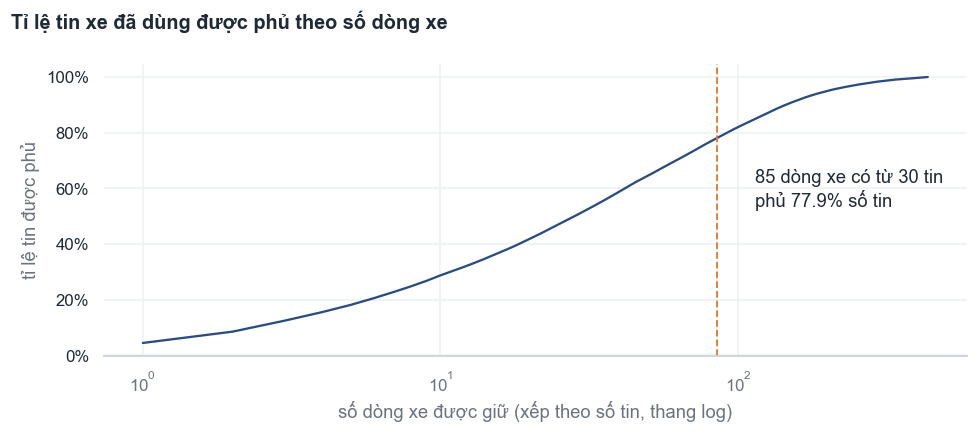

**Hình 5.** Sau các luật làm sạch còn 10 479 tin xe đã dùng thuộc 434 dòng xe. 85 dòng có từ 30 tin (không tính các nhóm `Dòng khác`) phủ 77.9% số tin; 212 dòng có dưới 5 tin. Bài toán giới hạn ở 85 dòng xe phổ biến này.

In [15]:
MIN_PRICE = 20e6
MIN_LISTINGS = 30

def apply_rules(df):
    """Luật cố định theo từng dòng (mục 3.1 - 3.6), không học từ dữ liệu."""
    out = df[(df["condition"] == "Đã sử dụng") & (df[TARGET] >= MIN_PRICE)].copy()
    out["seats"] = pd.to_numeric(out["seats"].replace("Khác", np.nan))
    age = CRAWL_YEAR - out["mfg_year"]
    fake_km = (out["mileage_km"] < 1000) & (age >= 2) | (out["mileage_km"] > 500_000)
    out.loc[fake_km, "mileage_km"] = np.nan
    out = out.sort_values("posted_at", ascending=False).drop_duplicates(DUP_KEY)
    out["brand_model"] = out["brand"] + " | " + out["model"]
    return out

ruled = apply_rules(raw)
model_counts = ruled["brand_model"].value_counts()
coverage = model_counts.cumsum() / len(ruled)
is_other = model_counts.index.str.endswith("| Dòng khác")
popular = model_counts[(model_counts >= MIN_LISTINGS) & ~is_other].index

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(np.arange(1, len(coverage) + 1), coverage.values, color=MAIN)
ax.axvline(len(popular), color=ACCENT, ls="--", lw=1.2)
ax.annotate(f"{len(popular)} dòng xe có từ {MIN_LISTINGS} tin\nphủ {pct(model_counts[popular].sum() / len(ruled))} số tin",
            (len(popular), coverage.iloc[len(popular) - 1]), xytext=(25, -45), textcoords="offset points", color=TEXT)
ax.set(xscale="log", xlabel="số dòng xe được giữ (xếp theo số tin, thang log)", ylabel="tỉ lệ tin được phủ",
       title="Tỉ lệ tin xe đã dùng được phủ theo số dòng xe")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1))
show_fig(fig, "scope",
    f"Sau các luật làm sạch còn {num(len(ruled))} tin xe đã dùng thuộc {len(model_counts)} dòng xe. "
    f"{len(popular)} dòng có từ {MIN_LISTINGS} tin (không tính các nhóm `Dòng khác`) phủ "
    f"{pct(model_counts[popular].sum() / len(ruled))} số tin; {(model_counts < 5).sum()} dòng có dưới 5 tin. Bài toán "
    f"giới hạn ở {len(popular)} dòng xe phổ biến này.")

### 3.9 Áp dụng luật làm sạch và chia train / validation / test

Tập dữ liệu được chia 70 / 15 / 15, phân tầng theo 10 khoảng giá (thập phân vị của log giá) để ba tập có phân phối giá
giống nhau. Từ đây, mọi phân tích và thống kê chỉ dùng tập train; validation dùng để chọn mô hình và test chỉ được chấm
một lần ở mục 7.

In [16]:
data = ruled[ruled["brand_model"].isin(popular)].reset_index(drop=True)
price_band = pd.qcut(np.log10(data[TARGET]), 10, labels=False)
train_df, rest = train_test_split(data, test_size=0.30, stratify=price_band, random_state=SEED)
val_df, test_df = train_test_split(rest, test_size=0.50, stratify=price_band[rest.index], random_state=SEED)
SPLITS = {"train": train_df, "val": val_df, "test": test_df}

display(pd.DataFrame({name: {"số tin": len(d), "% tin Hà Nội": round(100 * (d["city"] == "Hà Nội").mean(), 1),
                             "giá median (triệu)": round(d[TARGET].median() / 1e6), "số dòng xe": d["brand_model"].nunique()}
                      for name, d in SPLITS.items()}).T)
print(f"Từ {num(len(raw))} tin thô còn {num(len(data))} tin ({pct(len(data) / len(raw))}).")

,số tin,% tin Hà Nội,giá median (triệu),số dòng xe
train,5712.0,29.3,495.0,85.0
val,1224.0,29.3,490.0,85.0
test,1225.0,27.8,489.0,84.0


Từ 12 237 tin thô còn 8 161 tin (66.7%).


## 4. Phân tích khám phá (EDA)

Phần này chỉ dùng **tập train**.

### 4.1 Giá xe phân bố thế nào?

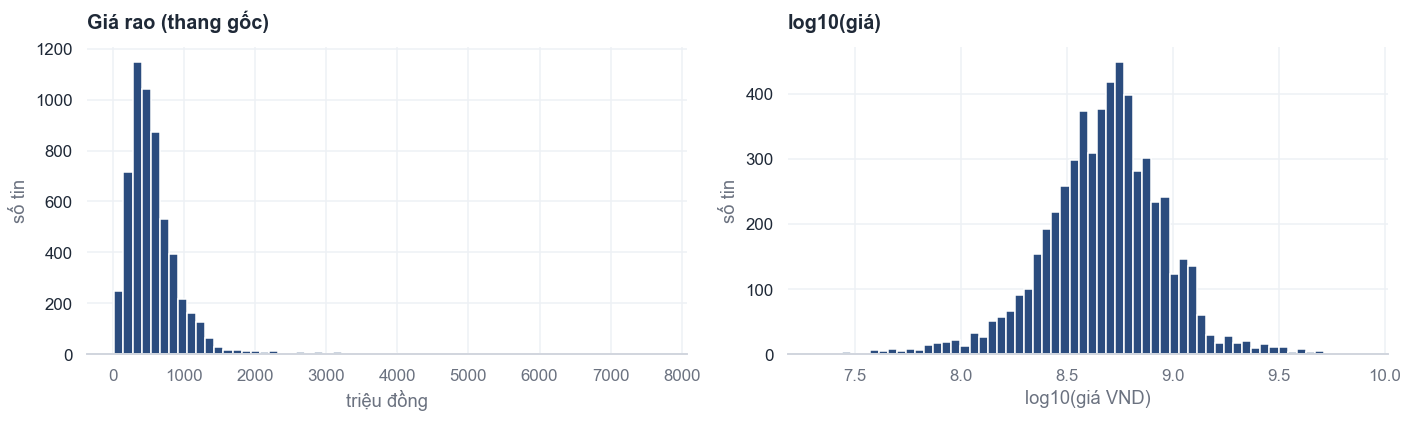

**Hình 6.** Giá ở thang gốc lệch phải mạnh (skew 4.21, median 495 triệu, trung bình 593 triệu). Sau khi lấy log10, phân phối gần đối xứng (skew -0.29). Mô hình sẽ học log10(giá): sai số trên thang log là sai số theo tỉ lệ, hợp với giá trải từ vài chục triệu tới vài tỷ.

In [17]:
eda = train_df.assign(age=CRAWL_YEAR - train_df["mfg_year"], log_price=np.log10(train_df[TARGET]))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(eda[TARGET] / 1e6, bins=60, color=MAIN)
axes[0].set(title="Giá rao (thang gốc)", xlabel="triệu đồng", ylabel="số tin")
axes[1].hist(eda["log_price"], bins=60, color=MAIN)
axes[1].set(title="log10(giá)", xlabel="log10(giá VND)", ylabel="số tin")
show_fig(fig, "target",
    f"Giá ở thang gốc lệch phải mạnh (skew {eda[TARGET].skew():.2f}, median {eda[TARGET].median() / 1e6:.0f} triệu, "
    f"trung bình {eda[TARGET].mean() / 1e6:.0f} triệu). Sau khi lấy log10, phân phối gần đối xứng (skew "
    f"{eda['log_price'].skew():.2f}). Mô hình sẽ học log10(giá): sai số trên thang log là sai số theo tỉ lệ, hợp với "
    f"giá trải từ vài chục triệu tới vài tỷ.")

### 4.2 Giá phụ thuộc vào dòng xe ra sao?

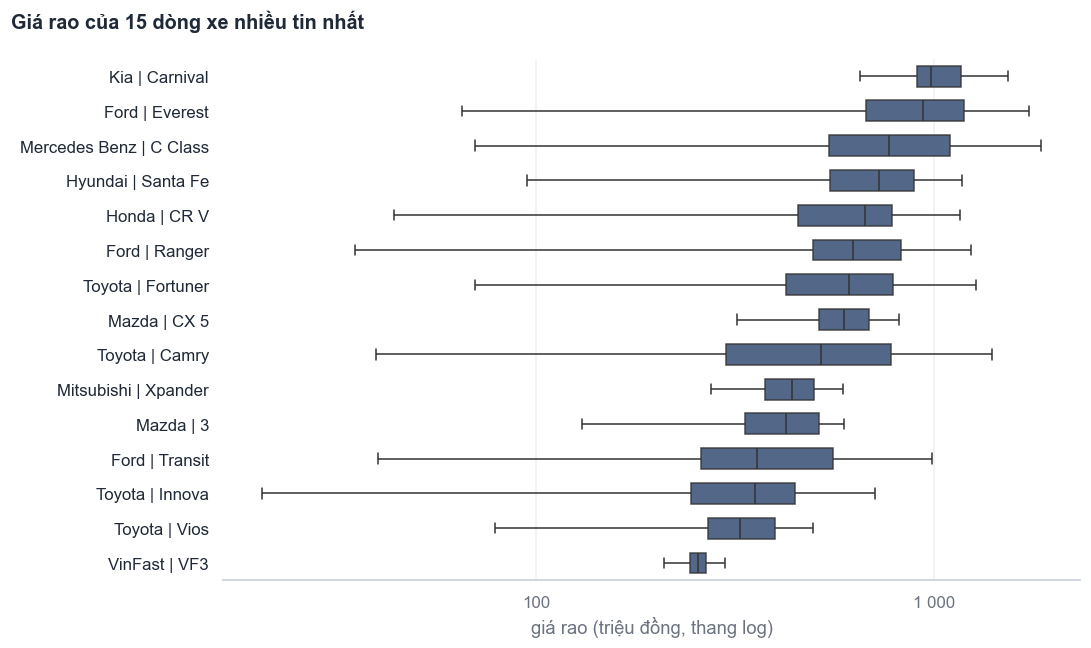

**Hình 7.** Median giá giữa các dòng xe chênh nhau tới 4 lần trong 15 dòng nhiều tin nhất, và chỉ riêng dòng xe đã giải thích 58% phương sai của log giá. Trong cùng một dòng, giá vẫn trải rộng (hộp dài) vì đời xe khác nhau.

In [18]:
top_models = eda["brand_model"].value_counts().head(15).index
order = eda[eda["brand_model"].isin(top_models)].groupby("brand_model")[TARGET].median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=eda[eda["brand_model"].isin(top_models)], y="brand_model", x=TARGET, order=order[::-1], color=MAIN,
            showfliers=False, width=0.6, ax=ax, boxprops={"alpha": 0.85})
ax.set(xscale="log", xlabel="giá rao (triệu đồng, thang log)", ylabel="", title="Giá rao của 15 dòng xe nhiều tin nhất")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(trieu))
model_med = eda.groupby("brand_model")[TARGET].median()
share_between = 1 - eda.groupby("brand_model")["log_price"].transform(lambda s: s - s.mean()).var() / eda["log_price"].var()
show_fig(fig, "price_by_model",
    f"Median giá giữa các dòng xe chênh nhau tới {model_med[top_models].max() / model_med[top_models].min():.0f} lần "
    f"trong 15 dòng nhiều tin nhất, và chỉ riêng dòng xe đã giải thích {pct(share_between, 0)} phương sai của log giá. "
    f"Trong cùng một dòng, giá vẫn trải rộng (hộp dài) vì đời xe khác nhau.")

### 4.3 Mỗi năm xe mất bao nhiêu giá, hãng nào giữ giá tốt nhất?

So giá giữa các hãng một cách trực tiếp sẽ bị lẫn với việc mỗi hãng bán những dòng xe khác nhau. Vì vậy, với mỗi hãng,
nhóm ước lượng hồi quy `log(giá) ~ tuổi xe + dòng xe` trên xe từ 1 đến 12 năm tuổi: hệ số của tuổi xe cho biết giá
giảm bao nhiêu phần trăm mỗi năm **khi so trong cùng một dòng xe**. Chỉ tính các hãng có từ 150 tin trong phạm vi này.

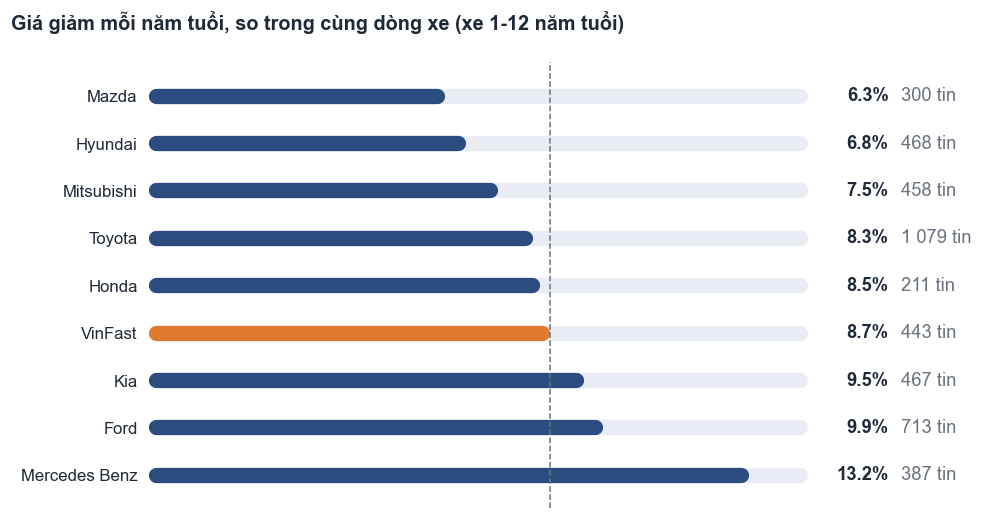

**Hình 8.** Tính chung, một chiếc xe mất khoảng 8.9% giá mỗi năm tuổi (đường nét đứt). Mazda giữ giá tốt nhất (6.3%/năm), Mercedes Benz mất giá nhanh nhất (13.2%/năm). Toyota (8.3%/năm) nằm ở giữa. VinFast (màu cam, phần lớn là xe điện) mất 8.7%/năm.

In [19]:
def yearly_loss(df):
    X_ = pd.get_dummies(df["brand_model"]).astype(float).assign(age=df["age"])
    coef = np.linalg.lstsq(X_.to_numpy(), np.log(df[TARGET]).to_numpy(), rcond=None)[0][-1]
    return 1 - np.exp(coef)

window = eda[eda["age"].between(1, 12)]
loss = pd.DataFrame([{"brand": b, "n": len(g), "loss": yearly_loss(g)}
                     for b, g in window.groupby("brand") if len(g) >= 150]).sort_values("loss")
overall_loss = yearly_loss(window)

fig, ax = plt.subplots(figsize=(9, 4.8))
hbars(ax, loss["brand"], loss["loss"], colors=[ACCENT if b == "VinFast" else MAIN for b in loss["brand"]],
      xmax=loss["loss"].max() * 1.1, ref=overall_loss, notes=[(pct(v), f"{num(n)} tin") for v, n in zip(loss["loss"], loss["n"])])
ax.set(title="Giá giảm mỗi năm tuổi, so trong cùng dòng xe (xe 1-12 năm tuổi)")
show_fig(fig, "depreciation_by_brand",
    f"Tính chung, một chiếc xe mất khoảng {pct(overall_loss)} giá mỗi năm tuổi (đường nét đứt). "
    f"{loss.iloc[0]['brand']} giữ giá tốt nhất ({pct(loss.iloc[0]['loss'])}/năm), "
    f"{loss.iloc[-1]['brand']} mất giá nhanh nhất ({pct(loss.iloc[-1]['loss'])}/năm). "
    f"Toyota ({pct(loss.set_index('brand').loc['Toyota', 'loss'])}/năm) nằm ở giữa. VinFast (màu cam, phần lớn là xe "
    f"điện) mất {pct(loss.set_index('brand').loc['VinFast', 'loss'])}/năm.")

### 4.4 Cùng dòng xe và cùng đời, số km ảnh hưởng thế nào?

Mỗi tin được chia cho giá median của các tin train cùng dòng xe và cùng năm sản xuất (chỉ tính nhóm có từ 5 tin), rồi
xem tỉ số này thay đổi theo số km.

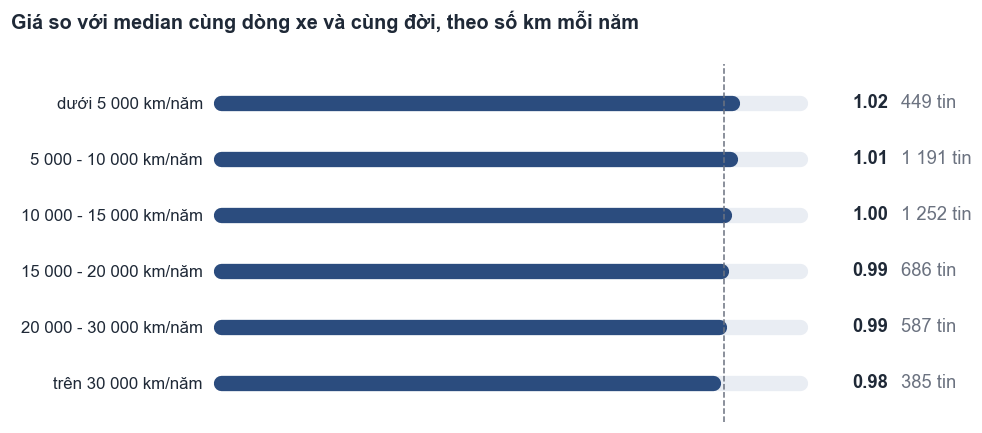

**Hình 9.** Khi đã cố định dòng xe và đời xe, xe chạy dưới 5 000 km/năm được rao 1.02 lần giá median, xe chạy trên 30 000 km/năm chỉ 0.98 lần. Ảnh hưởng của số km nhỏ hơn nhiều so với dòng xe và đời xe.

In [20]:
grp = eda["brand_model"] + "|" + eda["mfg_year"].astype(str)
same = eda[grp.map(grp.value_counts()) >= 5].copy()
same["relative"] = same[TARGET] / same.groupby(grp)[TARGET].transform("median")
same["km_per_year"] = same["mileage_km"] / same["age"].clip(lower=1)
bands = pd.cut(same["km_per_year"], [0, 5_000, 10_000, 15_000, 20_000, 30_000, np.inf],
               labels=["dưới 5 000", "5 000 - 10 000", "10 000 - 15 000", "15 000 - 20 000", "20 000 - 30 000", "trên 30 000"])
km_effect = same.groupby(bands, observed=True)["relative"].agg(["median", "size"])

fig, ax = plt.subplots(figsize=(9, 4))
hbars(ax, km_effect.index.astype(str) + " km/năm", km_effect["median"], xmax=1.15, ref=1,
      colors=[ACCENT if v < 0.97 else MAIN for v in km_effect["median"]],
      notes=[(f"{v:.2f}", f"{num(n)} tin") for v, n in zip(km_effect["median"], km_effect["size"])])
ax.set(title="Giá so với median cùng dòng xe và cùng đời, theo số km mỗi năm")
show_fig(fig, "km_effect",
    f"Khi đã cố định dòng xe và đời xe, xe chạy dưới 5 000 km/năm được rao "
    f"{km_effect['median'].iloc[0]:.2f} lần giá median, xe chạy trên 30 000 km/năm chỉ "
    f"{km_effect['median'].iloc[-1]:.2f} lần. Ảnh hưởng của số km nhỏ hơn nhiều so với dòng xe và đời xe.")

### 4.5 Thành phố và xuất xứ có làm giá khác đi không?

Với mỗi cặp (dòng xe, năm sản xuất) có tin ở cả hai nhóm, lấy tỉ số giá median giữa hai nhóm, rồi lấy median các tỉ số.

In [21]:
def paired_ratio(df, col, a, b):
    g = df[df[col].isin([a, b])].groupby(["brand_model", "mfg_year", col])[TARGET].median().unstack()
    g = g.dropna()
    return pd.Series({"so sánh": f"{a} / {b}", "số cặp dòng xe + đời": len(g), "tỉ số giá median": round((g[a] / g[b]).median(), 3)})

imported = eda["origin"].notna() & ~eda["origin"].isin(["Việt Nam", "Nước khác"])
eda_origin = eda.assign(origin_group=np.select([eda["origin"] == "Việt Nam", imported], ["lắp ráp trong nước", "nhập khẩu"], ""))
pairs = pd.DataFrame([paired_ratio(eda, "city", "Hà Nội", "TP.HCM"),
                      paired_ratio(eda_origin, "origin_group", "nhập khẩu", "lắp ráp trong nước"),
                      paired_ratio(eda.assign(shop=eda["seller_is_shop"].map({True: "salon", False: "cá nhân"})),
                                   "shop", "salon", "cá nhân")])
pairs

,so sánh,số cặp dòng xe + đời,tỉ số giá median
0,Hà Nội / TP.HCM,486,0.993
1,nhập khẩu / lắp ráp trong nước,241,0.995
2,salon / cá nhân,509,1.011


- **Nhận xét:** khi so cùng dòng xe và cùng đời, giá ở Hà Nội bằng 0.993 lần TP.HCM (486 cặp), xe nhập khẩu bằng 0.995
  lần xe lắp ráp trong nước (241 cặp), xe do salon bán bằng 1.011 lần xe của người bán cá nhân (509 cặp). Cả ba yếu tố
  gần như không làm giá khác đi. Chênh lệch giá thô giữa các nhóm này chủ yếu đến từ việc mỗi nhóm bán những dòng xe
  và đời xe khác nhau.

### 4.6 Các cột số: phân phối và tương quan

,count,mean,std,min,25%,50%,75%,max
log_price,5712.0,8.68,0.28,7.31,8.53,8.69,8.86,9.89
age,5712.0,6.16,4.75,0.00,3.00,5.00,8.00,39.00
log_km,5391.0,4.66,0.62,0.00,4.48,4.80,4.99,5.67
seats,4696.0,6.02,1.70,2.00,5.00,5.00,7.00,16.00
number_of_images,5712.0,11.26,5.32,0.00,7.00,11.00,15.00,46.00
seller_live_ads,5712.0,13.33,17.74,1.00,2.00,6.00,19.00,168.00
seller_sold_ads,3872.0,64.51,133.03,1.00,3.00,14.00,67.00,1980.00
seller_avg_rating,2674.0,4.58,0.77,1.00,4.50,5.00,5.00,5.00
seller_total_rating,2674.0,4.94,7.32,1.00,1.00,3.00,5.00,140.00


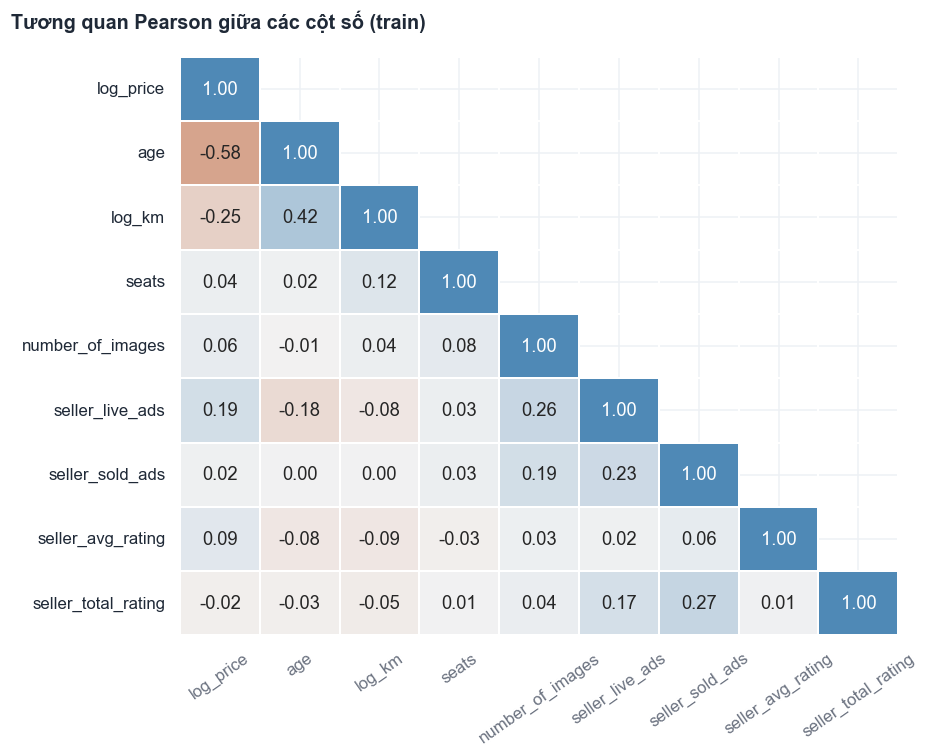

**Hình 10.** log giá tương quan âm mạnh nhất với tuổi xe (-0.58) và với log số km (-0.25); hai cột này cũng tương quan với nhau (0.42). Số ghế tương quan 0.04 với log giá. Các cột về người bán gần như không tương quan với giá (|r| ≤ 0.19).

In [22]:
num_view = eda.assign(log_km=np.log10(eda["mileage_km"] + 1))
NUM_VIEW = ["log_price", "age", "log_km", "seats", "number_of_images", "seller_live_ads", "seller_sold_ads",
            "seller_avg_rating", "seller_total_rating"]
display(num_view[NUM_VIEW].describe().T.round(2))

fig, ax = plt.subplots(figsize=(8.5, 7))
corr = num_view[NUM_VIEW].corr()
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), annot=True, fmt=".2f", vmin=-1, vmax=1,
            cmap=sns.diverging_palette(28, 240, s=70, l=55, as_cmap=True), cbar=False, linewidths=1, linecolor="white", ax=ax)
ax.set(title="Tương quan Pearson giữa các cột số (train)")
ax.tick_params(axis="x", rotation=35)
show_fig(fig, "correlation",
    f"log giá tương quan âm mạnh nhất với tuổi xe ({corr.loc['log_price', 'age']:.2f}) và với log số km "
    f"({corr.loc['log_price', 'log_km']:.2f}); hai cột này cũng tương quan với nhau ({corr.loc['age', 'log_km']:.2f}). "
    f"Số ghế tương quan {corr.loc['log_price', 'seats']:.2f} với log giá. Các cột về người bán gần như không tương quan "
    f"với giá (|r| ≤ {corr.loc['log_price', ['seller_live_ads', 'seller_sold_ads', 'seller_avg_rating', 'seller_total_rating']].abs().max():.2f}).")

### 4.7 Outlier

Ngoài quy tắc IQR trên từng cột, mỗi tin còn được so với **các tin train cùng dòng xe có năm sản xuất chênh không quá
2 năm** (cần ít nhất 3 tin để so): một chiếc xe rao gấp 3 lần, hoặc chưa tới 30% giá của những chiếc gần giống nó thì
nhiều khả năng giá bị nhập sai.

,% ngoài IQR
giá (thang gốc),4.6
log10(giá),3.7
số km,3.2
tuổi xe,6.4


Giá gấp hơn 3 lần xe cùng dòng, đời gần nhau: 7 tin; dưới 30%: 31 tin


,subject,mfg_year,mileage_km,price_vnd,relative
951,Bán xe Tucson bản full kịch trần năm 2018 tại HN,2019,86000.0,5250000000,9.13
5972,Xe Ford Ranger XLS 2.2L 4x2 AT 2019 - 435 Triệu,2019,130000.0,4355000000,8.38
394,TRANSIT 2023 GHẦM CAM MÁY RIN FULL PHỤ KIỆN,2023,145000.0,4880000000,8.13
8138,Mercedes-Benz E-Class E200 Exclusive 2023 Trắng,2023,2800.0,7690000003,5.50
8074,Mazda,2024,24000.0,3915000000,4.92
7453,Hyundai Grand i10 2017 Số sàn Đỏ,2017,NaN,888888888,4.50


,subject,mfg_year,mileage_km,price_vnd,relative
1131,innova 2015 Mũa bac xe dep không lỗi anh chị c...,2015,115000.0,20500000,0.07
5262,Mitsubishi Triton 5 chỗ Đen Tự động 2020,2020,11000.0,42000000,0.09
3664,Honda CR-V 2*** km Trắng,2016,146424.0,44000000,0.09
3867,Ford Ranger 2016 Máy dầu Số tự động Bạc,2016,NaN,35000000,0.09
6631,Toyota Camry 2.5Q 2015 Vàng cát 100000 km,2015,100000.0,46000000,0.10
8069,Toyota Fortuner 7 chỗ Đen 150.000km,2021,150000.0,70000000,0.10


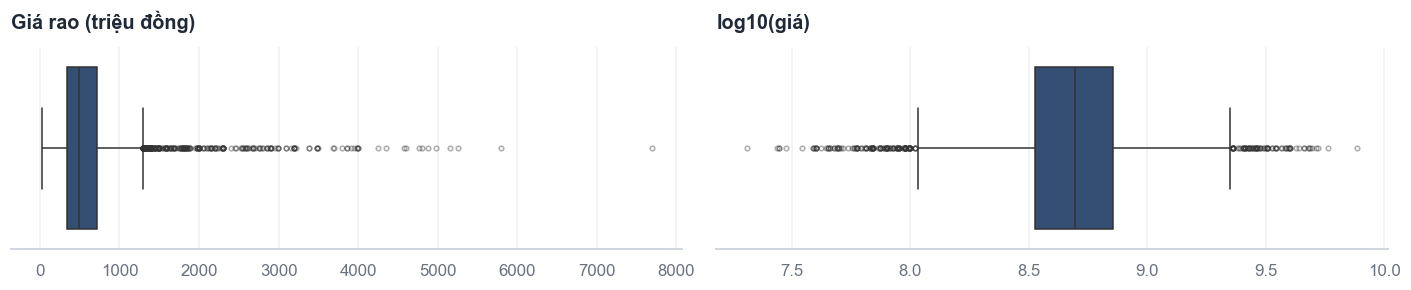

**Hình 11.** Theo quy tắc IQR, 4.6% giá ở thang gốc là outlier, chỉ còn 3.7% ở thang log. Phần lớn các tin này là xe sang hoặc xe rất cũ có thật. Lỗi giá thật sự chỉ lộ ra khi so với xe cùng dòng và đời gần nhau: 7 tin rao gấp hơn 3 lần và 31 tin dưới 30% giá của những chiếc gần giống.

In [23]:
LOW_RATIO, HIGH_RATIO = 0.30, 3.0
TRAIN_BY_MODEL = {m: g for m, g in train_df.groupby("brand_model")[["mfg_year", TARGET]]}


def reference_price(df):
    """Median giá của các tin train cùng dòng xe, năm sản xuất chênh không quá 2 năm (cần ít nhất 3 tin)."""
    ref = []
    for model, year in zip(df["brand_model"], df["mfg_year"]):
        near = TRAIN_BY_MODEL[model]
        near = near.loc[(near["mfg_year"] - year).abs() <= 2, TARGET]
        ref.append(near.median() if len(near) >= 3 else np.nan)
    return pd.Series(ref, index=df.index)


def iqr_share(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return ((s < q1 - 1.5 * (q3 - q1)) | (s > q3 + 1.5 * (q3 - q1))).mean()

outliers = pd.Series({"giá (thang gốc)": iqr_share(eda[TARGET]), "log10(giá)": iqr_share(eda["log_price"]),
                      "số km": iqr_share(eda["mileage_km"].dropna()), "tuổi xe": iqr_share(eda["age"])}, name="% ngoài IQR")
display((outliers * 100).round(1).to_frame())
eda["relative"] = eda[TARGET] / reference_price(eda)
too_high, too_low = eda["relative"] > HIGH_RATIO, eda["relative"] < LOW_RATIO
show_cols = ["subject", "mfg_year", "mileage_km", TARGET, "relative"]
print(f"Giá gấp hơn {HIGH_RATIO:.0f} lần xe cùng dòng, đời gần nhau: {too_high.sum()} tin; dưới {LOW_RATIO:.0%}: {too_low.sum()} tin")
display(eda.loc[too_high, show_cols].sort_values("relative", ascending=False).head(6).round(2))
display(eda.loc[too_low, show_cols].sort_values("relative").head(6).round(2))
fig, axes = plt.subplots(1, 2, figsize=(13, 2.8))
sns.boxplot(x=eda[TARGET] / 1e6, ax=axes[0], color=MAIN, flierprops={"markersize": 3, "alpha": 0.4})
axes[0].set(title="Giá rao (triệu đồng)", xlabel="")
sns.boxplot(x=eda["log_price"], ax=axes[1], color=MAIN, flierprops={"markersize": 3, "alpha": 0.4})
axes[1].set(title="log10(giá)", xlabel="")
show_fig(fig, "outliers",
    f"Theo quy tắc IQR, {pct(outliers['giá (thang gốc)'])} giá ở thang gốc là outlier, chỉ còn "
    f"{pct(outliers['log10(giá)'])} ở thang log. Phần lớn các tin này là xe sang hoặc xe rất cũ có thật. Lỗi giá thật sự "
    f"chỉ lộ ra khi so với xe cùng dòng và đời gần nhau: {too_high.sum()} tin rao gấp hơn {HIGH_RATIO:.0f} lần và "
    f"{too_low.sum()} tin dưới {LOW_RATIO:.0%} giá của những chiếc gần giống.")

### 4.8 Tổng kết EDA

- Giá lệch phải mạnh; mô hình học trên log10(giá) (mục 4.1).
- **Dòng xe** là yếu tố lớn nhất: riêng dòng xe giải thích 58% phương sai của log giá (mục 4.2).
- **Đời xe** đứng thứ hai: so trong cùng dòng xe, giá giảm trung bình 8.9% mỗi năm tuổi, từ 6.3% (Mazda) tới 13.2%
  (Mercedes Benz) (mục 4.3).
- Số km, thành phố, xuất xứ và loại người bán chỉ làm giá chênh vài phần trăm khi đã biết dòng xe và đời xe (mục 4.4,
  4.5).
- Tuổi xe và số km tương quan với nhau (0.42) nhưng không trùng thông tin; các cột về người bán gần như không tương quan
  với giá (mục 4.6).
- Lỗi giá chỉ lộ ra khi so với xe cùng loại: trong train có 7 tin giá cao và 31 tin giá thấp bất thường (mục 4.7), được
  bỏ ở mục 5.1.

## 5. Tiền xử lý dữ liệu

### 5.1 Bỏ tin có giá vô lý

Theo mục 4.7, bỏ các tin có giá dưới 30% hoặc trên 3 lần median giá của các tin train cùng dòng xe, năm sản xuất chênh
không quá 2 năm. Tin không đủ 3 xe để so thì được giữ. Median chỉ tính trên train rồi dùng lại cho validation và test.

In [24]:
for name, d in SPLITS.items():
    ratio = d[TARGET] / reference_price(d)
    wrong = (ratio < LOW_RATIO) | (ratio > HIGH_RATIO)
    SPLITS[name] = d[~wrong]
    print(f"{name}: bỏ {wrong.sum()} tin ({(ratio < LOW_RATIO).sum()} quá thấp, {(ratio > HIGH_RATIO).sum()} quá cao), "
          f"còn {num(len(SPLITS[name]))}")

train: bỏ 38 tin (31 quá thấp, 7 quá cao), còn 5 674
val: bỏ 3 tin (0 quá thấp, 3 quá cao), còn 1 221
test: bỏ 9 tin (8 quá thấp, 1 quá cao), còn 1 216


### 5.2 Tạo feature

- `age`: tuổi xe lúc thu thập (`2026 - mfg_year`), dễ hiểu hơn năm sản xuất và áp dụng được cho các năm sau.
- `log_km` = log10(số km + 1), vì số km lệch phải mạnh; `km_per_year` = số km / tuổi xe (tối thiểu 1 năm).
- Từ khóa trong tiêu đề: `kw_premium` (các bản cao cấp: Premium, Luxury, Limited, Platinum, Titanium, Wildtrak, AMG...),
  `kw_4x4` (dẫn động hai cầu), `kw_like_new` (lướt, như mới), `kw_finance` (vay, trả góp).

In [25]:
KEYWORDS = {
    "premium": r"premium|luxury|cao cấp|limited|signature|platinum|titanium|wildtrak|amg|\bfull\b",
    "4x4": r"4x4|4wd|awd|2 cầu|hai cầu",
    "like_new": r"lướt|như mới|mới tinh",
    "finance": r"vay|trả góp|trả trước",
}

def add_features(df):
    out = df.copy()
    out["age"] = CRAWL_YEAR - out["mfg_year"]
    out["log_km"] = np.log10(out["mileage_km"] + 1)
    out["km_per_year"] = out["mileage_km"] / out["age"].clip(lower=1)
    title = out["subject"].str.lower()
    for name, pattern in KEYWORDS.items():
        out[f"kw_{name}"] = title.str.contains(pattern).astype(int)
    out["seller_is_shop"] = out["seller_is_shop"].astype(int)
    return out

FEAT = {name: add_features(d) for name, d in SPLITS.items()}
FEAT["train"][[c for c in FEAT["train"] if c.startswith("kw_")]].mean().mul(100).round(1).rename("% tin train").to_frame().T

,kw_premium,kw_4x4,kw_like_new,kw_finance
% tin train,22.0,3.5,3.8,1.1


### 5.3 Điền giá trị thiếu

Từ mục 3.1 - 3.3, mỗi cột thiếu được xử lý theo nguyên nhân thiếu của nó:

| Cột | Thiếu (train) | Vì sao thiếu | Cách xử lý |
|---|---|---|---|
| `body_type`, `seats`, `origin` | xem bảng dưới | người bán bỏ trống; giá trị gần như được quyết định bởi dòng xe | điền giá trị phổ biến nhất **của cùng dòng xe** (học trên train), thêm cột cờ "bị thiếu" |
| `owners`, `has_registration`, `has_accessories`, `color` | | người bán bỏ trống; không suy ra được từ dòng xe | nhóm riêng `không rõ` |
| `mileage_km` (và `log_km`, `km_per_year`) | | số km ảo bị coi là thiếu (mục 3.2) | median của train + cột cờ |
| `seller_sold_ads`, `seller_avg_rating`, `seller_total_rating` | | người bán chưa có lượt bán / đánh giá nào | median của train + cột cờ |

Cách điền theo dòng xe được viết thành một transformer của scikit-learn để đặt trong `Pipeline`: `fit` chỉ học bảng
"dòng xe → giá trị phổ biến nhất" trên train. Dòng xe không có giá trị nào trong train thì dùng giá trị phổ biến nhất
của hãng, rồi của toàn bộ train.

In [26]:
def mode(s):
    s = s.dropna()
    return s.mode().iloc[0] if len(s) else np.nan


class GroupModeImputer(BaseEstimator, TransformerMixin):
    """Điền ô thiếu bằng giá trị phổ biến nhất trong cùng nhóm (dòng xe), nếu không có thì của nhóm cha (hãng),
    cuối cùng là của toàn bộ dữ liệu fit. Đầu vào gồm các cột cần điền cùng hai cột nhóm; đầu ra chỉ gồm các cột cần điền."""

    def __init__(self, columns, group="brand_model", parent="brand"):
        self.columns = columns
        self.group = group
        self.parent = parent

    def fit(self, X, y=None):
        self.by_group_ = {c: X.groupby(self.group)[c].agg(mode) for c in self.columns}
        self.by_parent_ = {c: X.groupby(self.parent)[c].agg(mode) for c in self.columns}
        self.overall_ = {c: mode(X[c]) for c in self.columns}
        return self

    def transform(self, X):
        out = X[self.columns].copy()
        for c in self.columns:
            out[c] = (out[c].fillna(X[self.group].map(self.by_group_[c]))
                            .fillna(X[self.parent].map(self.by_parent_[c]))
                            .fillna(self.overall_[c]))
        return out

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.columns, dtype=object)


MISSING_COLS = ["body_type", "seats", "origin", "owners", "has_registration", "has_accessories", "color",
                "mileage_km", "seller_sold_ads", "seller_avg_rating", "seller_total_rating"]
FEAT["train"][MISSING_COLS].isna().mean().mul(100).round(1).rename("% thiếu (train)").to_frame().T

,body_type,seats,origin,owners,has_registration,has_accessories,color,mileage_km,seller_sold_ads,seller_avg_rating,seller_total_rating
% thiếu (train),22.8,17.8,39.7,49.2,43.6,46.9,5.3,5.6,32.0,53.2,53.2


**Cách điền có đúng không?** Kiểm tra trực tiếp: trên train, giấu ngẫu nhiên 20% số ô **đang có giá trị** của một cột,
điền lại bằng hai cách rồi so với giá trị thật. Lặp 5 lần với 5 cách giấu khác nhau.

- **Giá trị phổ biến nhất chung:** một giá trị cho mọi ô thiếu (cách điền mặc định của `SimpleImputer(strategy="most_frequent")`).
- **Giá trị phổ biến nhất của cùng dòng xe:** `GroupModeImputer` ở trên, học trên phần còn lại của train.

,giá trị phổ biến nhất chung,giá trị phổ biến nhất của dòng xe
body_type,41.7% ± 2.6,90.4% ± 0.8
seats,52.5% ± 1.0,91.0% ± 0.6
origin,52.6% ± 0.8,66.7% ± 1.6
color,34.6% ± 1.1,38.8% ± 0.7
owners,87.8% ± 0.6,87.7% ± 0.7
has_registration,99.1% ± 0.4,99.1% ± 0.4


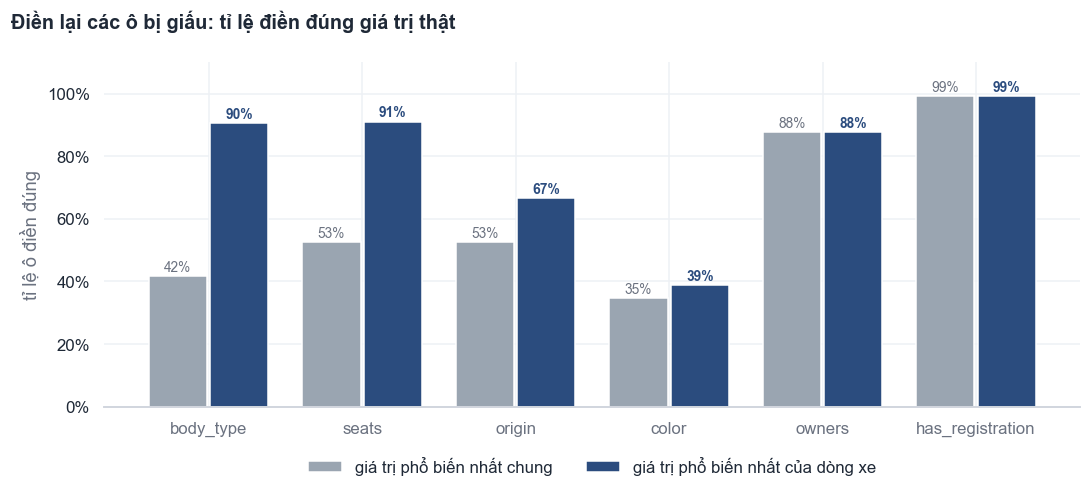

**Hình 12.** Điền theo dòng xe đúng 90% với `body_type`, 91% với `seats` và 67% với `origin`, cao hơn điền một giá trị chung 49, 38 và 14 điểm %. Với `color`, `owners`, `has_registration`, điền theo dòng xe gần như không hơn điền chung (chênh không quá 4 điểm %): các cột này không suy ra được từ dòng xe, nên được để thành nhóm `không rõ`.

In [27]:
def masked_accuracy(df, column, frac=0.2, repeats=5):
    rng = np.random.default_rng(SEED)
    known = df.index[df[column].notna()]
    result = {"giá trị phổ biến nhất chung": [], "giá trị phổ biến nhất của dòng xe": []}
    for _ in range(repeats):
        hidden_idx = rng.choice(known, int(frac * len(known)), replace=False)
        masked = df.copy()
        masked.loc[hidden_idx, column] = np.nan
        truth = df.loc[hidden_idx, column]
        result["giá trị phổ biến nhất chung"].append((truth == mode(masked[column])).mean())
        filled = GroupModeImputer([column]).fit(masked).transform(masked.loc[hidden_idx])[column]
        result["giá trị phổ biến nhất của dòng xe"].append((truth == filled).mean())
    return {k: (np.mean(v), np.std(v)) for k, v in result.items()}

CHECK_COLS = ["body_type", "seats", "origin", "color", "owners", "has_registration"]
acc = {c: masked_accuracy(FEAT["train"], c) for c in CHECK_COLS}
acc_table = pd.DataFrame({c: {k: f"{100 * m:.1f}% ± {100 * s:.1f}" for k, (m, s) in v.items()} for c, v in acc.items()}).T
display(acc_table)

fig, ax = plt.subplots(figsize=(10, 4.6))
x = np.arange(len(CHECK_COLS))
plain = [acc[c]["giá trị phổ biến nhất chung"][0] for c in CHECK_COLS]
grouped = [acc[c]["giá trị phổ biến nhất của dòng xe"][0] for c in CHECK_COLS]
ax.bar(x - 0.2, plain, 0.38, color=GREY, label="giá trị phổ biến nhất chung")
ax.bar(x + 0.2, grouped, 0.38, color=MAIN, label="giá trị phổ biến nhất của dòng xe")
for xi, (a, b) in enumerate(zip(plain, grouped)):
    ax.text(xi - 0.2, a + 0.015, pct(a, 0), ha="center", color=MUTED, fontsize=9)
    ax.text(xi + 0.2, b + 0.015, pct(b, 0), ha="center", color=MAIN, fontsize=9, fontweight="bold")
ax.set_xticks(x, CHECK_COLS)
ax.set(ylim=(0, 1.1), ylabel="tỉ lệ ô điền đúng", title="Điền lại các ô bị giấu: tỉ lệ điền đúng giá trị thật")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
gain = {c: grouped[i] - plain[i] for i, c in enumerate(CHECK_COLS)}
show_fig(fig, "imputation_check",
    f"Điền theo dòng xe đúng {pct(acc['body_type']['giá trị phổ biến nhất của dòng xe'][0], 0)} với `body_type`, "
    f"{pct(acc['seats']['giá trị phổ biến nhất của dòng xe'][0], 0)} với `seats` và "
    f"{pct(acc['origin']['giá trị phổ biến nhất của dòng xe'][0], 0)} với `origin`, cao hơn điền một giá trị chung "
    f"{100 * gain['body_type']:.0f}, {100 * gain['seats']:.0f} và {100 * gain['origin']:.0f} điểm %. Với `color`, `owners`, "
    f"`has_registration`, điền theo dòng xe gần như không hơn điền chung (chênh không quá "
    f"{100 * max(abs(gain[c]) for c in ['color', 'owners', 'has_registration']):.0f} điểm %): các cột này không suy ra được từ "
    f"dòng xe, nên được để thành nhóm `không rõ`.")

- **Nhận xét:** với `owners` và `has_registration`, tỉ lệ điền đúng cao (88% và 99%) chỉ vì gần như mọi ô có giá trị
  đều là `1 chủ` và `Có`. Ô trống ở hai cột này có thể không ngẫu nhiên: người bán có xe nhiều đời chủ hoặc hết đăng kiểm
  có lý do để bỏ qua mục đó. Điền `1 chủ` hay `Có` sẽ xóa mất khả năng này.
- **Quyết định:** `body_type`, `seats`, `origin` được điền theo dòng xe; `color`, `owners`, `has_registration`,
  `has_accessories` giữ nhóm riêng `không rõ` để mô hình tự học xem việc bỏ trống có ý nghĩa gì không.

### 5.4 - 5.5 Mã hóa và chuẩn hóa

Tất cả các bước điền thiếu, mã hóa và chuẩn hóa được gói trong một `ColumnTransformer` đặt đầu `Pipeline` của mỗi mô
hình, nên mọi thống kê (giá trị phổ biến theo dòng xe, median, mean, std, giá trung bình theo dòng xe) chỉ học từ train.

| Nhóm | Cột | Điền thiếu | Mã hóa / chuẩn hóa |
|---|---|---|---|
| Số | `age`, `log_km`, `km_per_year`, `number_of_images`, các cột người bán | median + cột cờ | `StandardScaler` |
| Suy ra từ dòng xe | `seats` (số), `body_type`, `origin` (phân loại) | `GroupModeImputer` + cột cờ | `StandardScaler` / one-hot |
| Phân loại ít mức | `city`, `fuel`, `gearbox`, `color`, `owners`, `has_registration`, `has_accessories` | nhóm `không rõ` | one-hot |
| Phân loại nhiều mức | `brand`, `brand_model`, `district` | (không thiếu) | target encoding rồi `StandardScaler`; thêm one-hot cho các mức có từ 5 tin |
| Cờ 0/1 | `seller_is_shop`, `kw_*` | không thiếu | giữ nguyên |

**Target encoding** thay mỗi mức (ví dụ dòng `Toyota | Innova`) bằng giá trung bình (log) của các xe thuộc mức đó trong
train, có làm mượt: mức có ít tin được kéo về gần giá trung bình chung. Lớp `TargetEncoder` của scikit-learn dùng
cross-fitting khi `fit_transform` trên train (giá trị của mỗi dòng tính từ các fold khác) để mô hình không "thấy trước"
target của chính dòng đó.

In [28]:
NUM_COLS = ["age", "log_km", "km_per_year", "number_of_images", "seller_live_ads", "seller_sold_ads",
            "seller_avg_rating", "seller_total_rating"]
INFER_NUM, INFER_CAT = ["seats"], ["body_type", "origin"]
LOW_CAT = ["city", "fuel", "gearbox", "color", "owners", "has_registration", "has_accessories"]
HIGH_CAT = ["brand", "brand_model", "district"]
FLAGS = ["seller_is_shop"] + [f"kw_{k}" for k in KEYWORDS]
FEATURES = NUM_COLS + INFER_NUM + INFER_CAT + LOW_CAT + HIGH_CAT + FLAGS
GROUP_COLS = ["brand_model", "brand"]


def onehot(min_frequency):
    return make_pipeline(SimpleImputer(strategy="constant", fill_value="không rõ"),
                         OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=min_frequency, sparse_output=False))


def make_preprocess(impute="by_model"):
    """impute = "by_model": điền seats, body_type, origin theo dòng xe; "simple": median / nhóm "không rõ"."""
    if impute == "by_model":
        infer = [("seats", make_pipeline(GroupModeImputer(INFER_NUM), StandardScaler()), INFER_NUM + GROUP_COLS),
                 ("infer", make_pipeline(GroupModeImputer(INFER_CAT), OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
                  INFER_CAT + GROUP_COLS)]
    else:
        infer = [("seats", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), INFER_NUM),
                 ("infer", onehot(20), INFER_CAT)]
    return ColumnTransformer([
        ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), NUM_COLS),
        *infer,
        ("flag_missing", MissingIndicator(features="all"), INFER_NUM + INFER_CAT),
        ("low", onehot(20), LOW_CAT),
        ("te", make_pipeline(TargetEncoder(target_type="continuous", random_state=SEED), StandardScaler()), HIGH_CAT),
        ("oh", onehot(5), HIGH_CAT),
        ("flag", "passthrough", FLAGS),
    ], verbose_feature_names_out=False)


X = {name: d[FEATURES] for name, d in FEAT.items()}
y = {name: np.log10(d[TARGET]).to_numpy() for name, d in FEAT.items()}
pre = make_preprocess().fit(X["train"], y["train"])
print("Số cột sau tiền xử lý:", pre.transform(X["train"]).shape[1])

Số cột sau tiền xử lý: 222


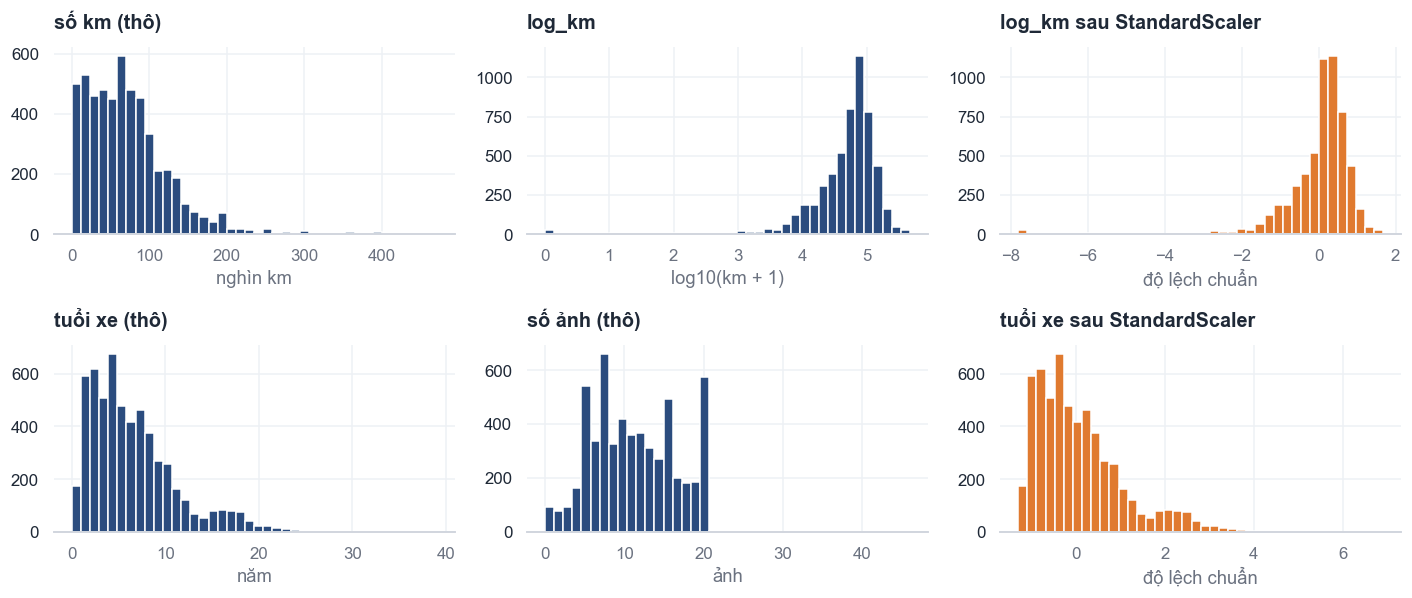

**Hình 13.** Số km thô lệch phải (skew 1.74). Lấy log10 gom phần lớn tin vào khoảng 3.8 - 5.2, đổi lại có một đuôi trái gồm các xe gần như mới (7% tin dưới 10 000 km). StandardScaler (màu cam) không đổi hình dạng phân phối mà chỉ dời về trung bình 0 và độ lệch chuẩn 1 (log_km: -0.00 và 1.00), để các cột có cùng thang đo trước khi vào hồi quy tuyến tính và kNN.

In [29]:
scaled = pd.DataFrame(pre.named_transformers_["num"].transform(X["train"][NUM_COLS])[:, :len(NUM_COLS)], columns=NUM_COLS)
fig, axes = plt.subplots(2, 3, figsize=(13, 5.6))
views = [("số km (thô)", FEAT["train"]["mileage_km"] / 1000, "nghìn km"),
         ("log_km", FEAT["train"]["log_km"], "log10(km + 1)"),
         ("log_km sau StandardScaler", scaled["log_km"], "độ lệch chuẩn"),
         ("tuổi xe (thô)", FEAT["train"]["age"], "năm"),
         ("số ảnh (thô)", FEAT["train"]["number_of_images"], "ảnh"),
         ("tuổi xe sau StandardScaler", scaled["age"], "độ lệch chuẩn")]
for ax, (title, values, xlabel) in zip(axes.flat, views):
    ax.hist(values.dropna(), bins=40, color=ACCENT if "Scaler" in title else MAIN)
    ax.set(title=title, xlabel=xlabel)
show_fig(fig, "scaling",
    f"Số km thô lệch phải (skew {FEAT['train']['mileage_km'].skew():.2f}). Lấy log10 gom phần lớn tin vào khoảng "
    f"{FEAT['train']['log_km'].quantile(0.05):.1f} - {FEAT['train']['log_km'].quantile(0.95):.1f}, đổi lại có một đuôi trái "
    f"gồm các xe gần như mới ({pct((FEAT['train']['mileage_km'] < 10_000).mean(), 0)} tin dưới 10 000 km). StandardScaler (màu cam) không đổi hình dạng phân phối mà chỉ dời về "
    f"trung bình 0 và độ lệch chuẩn 1 (log_km: {scaled['log_km'].mean():.2f} và {scaled['log_km'].std():.2f}), để các cột "
    f"có cùng thang đo trước khi vào hồi quy tuyến tính và kNN.")

## 6. Xây dựng mô hình

### 6.1 Thước đo và cách chọn mô hình

- **Thước đo chính: R² trên log10(giá)**: mô hình giải thích được bao nhiêu phần biến động của giá (1 là hoàn hảo, 0
  là bằng đoán giá trung bình). Trên thang log, R² đo sai số theo tỉ lệ chứ không theo số tiền.
- **Thước đo dễ hiểu:** sai số tuyệt đối theo % giá thật, lấy median trên các tin (`median_APE`), và tỉ lệ tin đoán
  lệch không quá 10% (`within_10`). MAE tính bằng triệu đồng cũng được báo cáo.
- **Cách chọn:** mỗi mô hình được chấm bằng cross-validation 5 fold trên train (`KFold`, xáo trộn, seed 261), rồi huấn
  luyện lại trên toàn train và chấm trên validation. Mô hình có R² validation cao nhất được chọn. Hai mô hình chỉ được
  coi là khác nhau khi hiệu R² lớn hơn độ lệch giữa các fold; nếu nhỏ hơn, chọn mô hình có sai số % median trên
  validation thấp hơn. Tập test chỉ được chấm ở mục 7.

In [30]:
KF = KFold(n_splits=5, shuffle=True, random_state=SEED)


def scores(y_true, y_pred):
    true, pred = 10 ** y_true, 10 ** y_pred
    ape = np.abs(pred - true) / true
    return {"R2": r2_score(y_true, y_pred), "median_APE_%": 100 * np.median(ape),
            "within_10_%": 100 * np.mean(ape <= 0.10), "MAE_trieu": np.mean(np.abs(pred - true)) / 1e6}


def evaluate(name, model, split="val", cv=True):
    row = {"model": name}
    if cv:
        res = cross_validate(model, X["train"], y["train"], cv=KF, scoring="r2", n_jobs=-1)
        row.update(cv_R2=res["test_score"].mean(), cv_R2_std=res["test_score"].std())
    model.fit(X["train"], y["train"])
    row.update({f"{split}_{k}": v for k, v in scores(y[split], model.predict(X[split])).items()})
    return row, model


def pipe(model, impute="by_model"):
    return make_pipeline(make_preprocess(impute), model)

### 6.2 Baseline

1. **Luôn đoán giá trung bình của train** (`DummyRegressor`).
2. **Đoán giá median của các xe cùng dòng và cùng năm sản xuất** trên train; nếu nhóm đó không có tin thì dùng median
   của dòng xe. Đây là cách một người mua thường tra giá: "Innova 2019 trên chợ đang rao khoảng bao nhiêu".

In [31]:
class GroupMedianRegressor(BaseEstimator, RegressorMixin):
    """Dự đoán median của target trong cùng (dòng xe, năm sản xuất); nếu không có thì median của dòng xe, rồi median chung."""

    def fit(self, X, y):
        y = pd.Series(y, index=X.index)
        self.by_year_ = y.groupby([X["brand_model"], CRAWL_YEAR - X["age"]]).median()
        self.by_model_ = y.groupby(X["brand_model"]).median()
        self.overall_ = y.median()
        return self

    def predict(self, X):
        keys = pd.MultiIndex.from_arrays([X["brand_model"], CRAWL_YEAR - X["age"]])
        pred = pd.Series(self.by_year_.reindex(keys).to_numpy(), index=X.index)
        return pred.fillna(X["brand_model"].map(self.by_model_)).fillna(self.overall_).to_numpy()


rows, FITTED = [], {}
for name, model in [("Baseline: giá trung bình", DummyRegressor(strategy="mean")),
                    ("Baseline: median cùng dòng xe và đời", GroupMedianRegressor())]:
    row, FITTED[name] = evaluate(name, model)
    rows.append(row)
pd.DataFrame(rows).round(3)

,model,cv_R2,cv_R2_std,val_R2,val_median_APE_%,val_within_10_%,val_MAE_trieu
0,Baseline: giá trung bình,-0.001,0.001,-0.00,36.298,14.578,260.196
1,Baseline: median cùng dòng xe và đời,0.858,0.009,0.82,6.579,63.391,69.095


### 6.3 So sánh các mô hình hồi quy

Năm mô hình dùng chung bộ tiền xử lý ở mục 5: hồi quy tuyến tính, kNN, cây quyết định, random forest và gradient
boosting (`HistGradientBoostingRegressor`).

In [32]:
MODELS = {
    "Hồi quy tuyến tính": pipe(LinearRegression()),
    "kNN (k=10)": pipe(KNeighborsRegressor(n_neighbors=10, weights="distance")),
    "Cây quyết định (sâu 12)": pipe(DecisionTreeRegressor(max_depth=12, min_samples_leaf=5, random_state=SEED)),
    "Random forest": pipe(RandomForestRegressor(n_estimators=300, max_features=0.5, n_jobs=-1, random_state=SEED)),
    "Gradient boosting": pipe(HistGradientBoostingRegressor(learning_rate=0.05, max_iter=600, max_leaf_nodes=31,
                                                            l2_regularization=1.0, random_state=SEED)),
}
for name, model in MODELS.items():
    row, FITTED[name] = evaluate(name, model)
    rows.append(row)
val_res = pd.DataFrame(rows)
val_res.round(3)

,model,cv_R2,cv_R2_std,val_R2,val_median_APE_%,val_within_10_%,val_MAE_trieu
0,Baseline: giá trung bình,-0.001,0.001,-0.000,36.298,14.578,260.196
1,Baseline: median cùng dòng xe và đời,0.858,0.009,0.820,6.579,63.391,69.095
2,Hồi quy tuyến tính,0.928,0.004,0.923,8.014,57.002,69.256
3,kNN (k=10),0.791,0.012,0.791,14.632,34.726,115.710
4,Cây quyết định (sâu 12),0.919,0.007,0.924,7.796,59.132,65.201
5,Random forest,0.946,0.004,0.953,5.606,70.188,50.389
6,Gradient boosting,0.949,0.004,0.953,5.996,69.861,51.459


- **Nhận xét:**
  - Random forest và gradient boosting tốt nhất, cùng R² validation 0.953, sai số % median 5.6% và 6.0%.
  - Baseline median cùng dòng xe và đời đã khá mạnh (sai số 6.6%): biết dòng xe và năm sản xuất là đoán được gần đúng
    giá. Hai mô hình cây giảm thêm sai số nhờ số km, phiên bản (từ khóa trong tiêu đề) và các xe thuộc nhóm (dòng xe,
    năm) có ít tin, nơi baseline phải dùng median của cả dòng xe. R² của baseline (0.820) thấp hơn hồi quy tuyến tính
    vì chính những tin này bị đoán lệch nhiều.
  - Hồi quy tuyến tính đạt R² 0.923 nhờ target encoding và one-hot của dòng xe, nhưng sai số % median (8.0%) cao hơn
    baseline: một đường thẳng trên log giá không mô tả được việc mỗi dòng xe mất giá với tốc độ khác nhau.
  - kNN kém nhất (0.791): khoảng cách được tính trên hơn 200 cột sau one-hot, phần lớn là cột dòng xe và quận, nên
    những láng giềng gần nhất không còn là những chiếc xe thật sự giống nhau.

### 6.4 Ảnh hưởng của tham số

`max_depth` của cây, `k` của kNN và số vòng lặp của gradient boosting là hyperparameter: không học từ dữ liệu mà do
người làm chọn. Hình dưới thay đổi từng tham số và chấm R² trên train và validation.

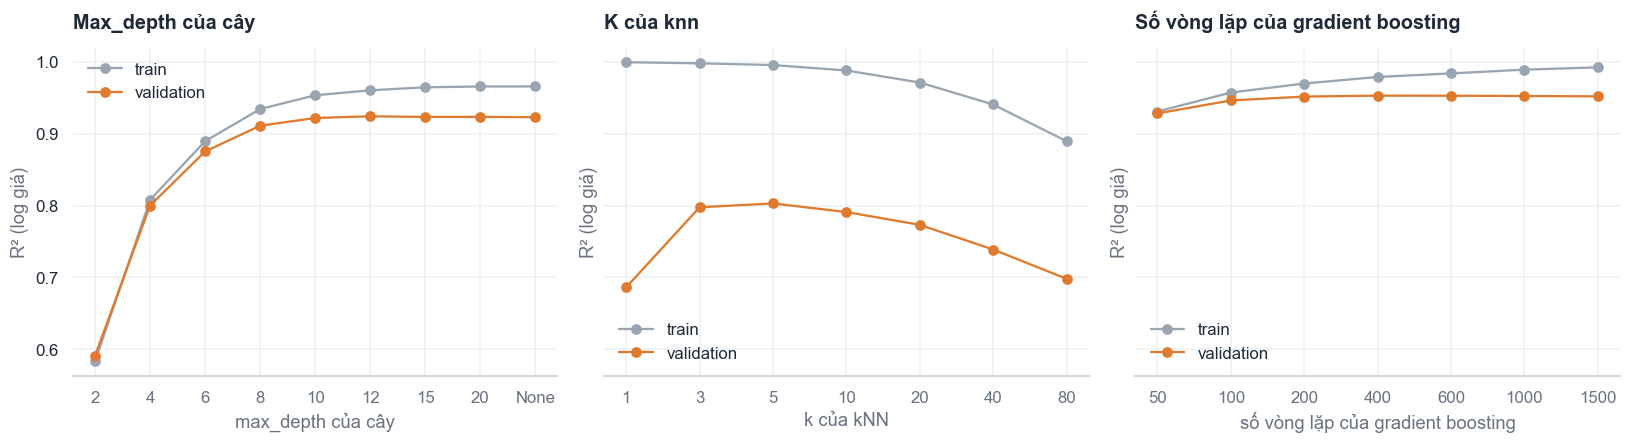

**Hình 14.** Cây càng sâu thì R² train càng tăng (0.966 khi không giới hạn) và khoảng cách giữa train và validation càng lớn (từ 0.008 ở max_depth=4 lên 0.043): cây sâu bắt đầu học thuộc train. R² validation cao nhất là 0.924 ở max_depth=12. kNN tốt nhất ở k=5 (R² validation 0.803). Gradient boosting tăng nhanh đến khoảng 400 vòng lặp (R² validation 0.953) rồi gần như đi ngang.

In [33]:
def sweep(make, values):
    out = []
    for v in values:
        m = make(v).fit(X["train"], y["train"])
        out.append({"value": str(v), "train": r2_score(y["train"], m.predict(X["train"])),
                    "val": r2_score(y["val"], m.predict(X["val"]))})
    return pd.DataFrame(out)

tree_sweep = sweep(lambda d: pipe(DecisionTreeRegressor(max_depth=d, min_samples_leaf=5, random_state=SEED)),
                   [2, 4, 6, 8, 10, 12, 15, 20, None])
knn_sweep = sweep(lambda k: pipe(KNeighborsRegressor(n_neighbors=k, weights="distance")), [1, 3, 5, 10, 20, 40, 80])
hgb_sweep = sweep(lambda n: pipe(HistGradientBoostingRegressor(learning_rate=0.05, max_iter=n, max_leaf_nodes=31,
                                                               l2_regularization=1.0, random_state=SEED)),
                  [50, 100, 200, 400, 600, 1000, 1500])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, sw, label in [(axes[0], tree_sweep, "max_depth của cây"), (axes[1], knn_sweep, "k của kNN"),
                      (axes[2], hgb_sweep, "số vòng lặp của gradient boosting")]:
    ax.plot(sw["value"], sw["train"], marker="o", color=GREY, label="train")
    ax.plot(sw["value"], sw["val"], marker="o", color=ACCENT, label="validation")
    ax.set(xlabel=label, ylabel="R² (log giá)", title=label.capitalize())
    ax.legend()
best = {n: s.loc[s["val"].idxmax()] for n, s in [("tree", tree_sweep), ("knn", knn_sweep), ("hgb", hgb_sweep)]}
show_fig(fig, "hyperparameters",
    f"Cây càng sâu thì R² train càng tăng ({tree_sweep['train'].iloc[-1]:.3f} khi không giới hạn) và khoảng cách giữa "
    f"train và validation càng lớn (từ {tree_sweep['train'].iloc[1] - tree_sweep['val'].iloc[1]:.3f} ở max_depth=4 lên "
    f"{tree_sweep['train'].iloc[-1] - tree_sweep['val'].iloc[-1]:.3f}): cây sâu bắt đầu học thuộc train. R² validation cao "
    f"nhất là {best['tree']['val']:.3f} ở max_depth={best['tree']['value']}. kNN tốt nhất ở k={best['knn']['value']} (R² validation {best['knn']['val']:.3f}). "
    f"Gradient boosting tăng nhanh đến khoảng {best['hgb']['value']} vòng lặp (R² validation {best['hgb']['val']:.3f}) "
    f"rồi gần như đi ngang.")

### 6.5 Cách điền giá trị thiếu ảnh hưởng tới mô hình ra sao?

Mục 5.3 cho thấy điền theo dòng xe đúng hơn với từng ô. Câu hỏi tiếp theo là điều đó có làm mô hình dự đoán giá tốt
hơn không. Random forest (cùng tham số như mục 6.3) được huấn luyện theo ba cách:

1. **Bỏ tin có ô thiếu:** bỏ khỏi train mọi tin thiếu `body_type`, `seats` hoặc `origin`; khi dự đoán, ô thiếu được điền
   đơn giản như cách 2.
2. **Điền đơn giản:** median cho `seats`, nhóm `không rõ` cho `body_type`, `origin`, kèm cột cờ.
3. **Điền theo dòng xe:** `GroupModeImputer` kèm cột cờ (cách đang dùng).

Cả ba được chấm trên toàn bộ validation và riêng trên các tin validation có ít nhất một trong ba cột bị thiếu.

,cách,số tin train,R2 (toàn bộ val),median_APE_% (toàn bộ val),R2 (612 tin val có ô thiếu),median_APE_% (tin có ô thiếu)
0,bỏ tin có ô thiếu,2782,0.939,6.699,0.935,7.576
1,điền đơn giản,5674,0.953,5.698,0.954,6.310
2,điền theo dòng xe,5674,0.953,5.606,0.955,5.817


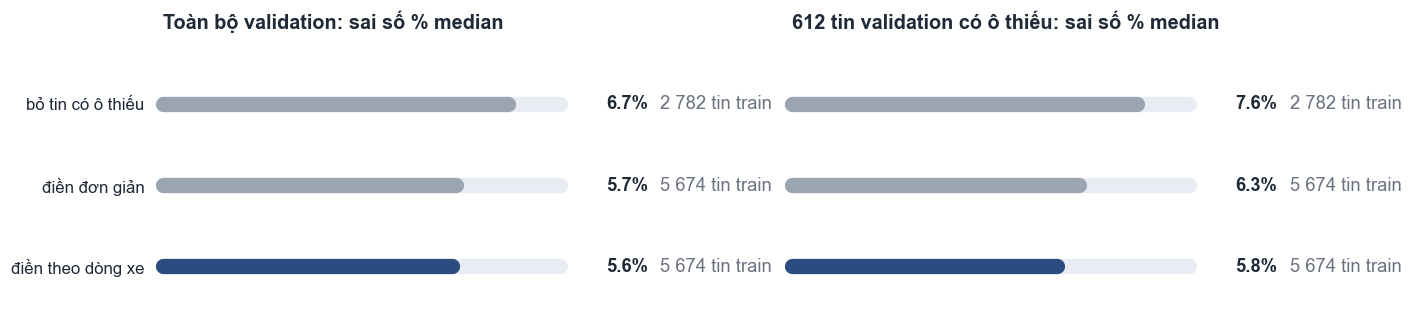

**Hình 15.** Bỏ tin có ô thiếu làm mất 51% train và cho sai số cao nhất. Điền theo dòng xe cho sai số 5.6% trên toàn bộ validation so với 5.7% của điền đơn giản; trên các tin có ô thiếu là 5.8% so với 6.3%.

In [34]:
INFER_ALL = INFER_NUM + INFER_CAT
complete_train = X["train"][INFER_ALL].notna().all(axis=1).to_numpy()
has_gap_val = X["val"][INFER_ALL].isna().any(axis=1).to_numpy()
make_rf = lambda impute: pipe(RandomForestRegressor(n_estimators=300, max_features=0.5, n_jobs=-1, random_state=SEED), impute)

variants = [("bỏ tin có ô thiếu", make_rf("simple").fit(X["train"][complete_train], y["train"][complete_train]), complete_train.sum()),
            ("điền đơn giản", make_rf("simple").fit(X["train"], y["train"]), len(y["train"])),
            ("điền theo dòng xe", FITTED["Random forest"], len(y["train"]))]
imp_rows = []
for name, model, n_train in variants:
    pred = model.predict(X["val"])
    full, gaps = scores(y["val"], pred), scores(y["val"][has_gap_val], pred[has_gap_val])
    imp_rows.append({"cách": name, "số tin train": n_train, "R2 (toàn bộ val)": full["R2"],
                     "median_APE_% (toàn bộ val)": full["median_APE_%"],
                     f"R2 ({has_gap_val.sum()} tin val có ô thiếu)": gaps["R2"],
                     "median_APE_% (tin có ô thiếu)": gaps["median_APE_%"]})
imp_res = pd.DataFrame(imp_rows)
display(imp_res.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.2), sharey=True)
for ax, col, title in [(axes[0], "median_APE_% (toàn bộ val)", "Toàn bộ validation"),
                       (axes[1], "median_APE_% (tin có ô thiếu)", f"{has_gap_val.sum()} tin validation có ô thiếu")]:
    vals = imp_res[col]
    hbars(ax, imp_res["cách"], vals, colors=[GREY, GREY, MAIN], xmax=vals.max() * 1.15,
          notes=[(f"{v:.1f}%", f"{num(n)} tin train") for v, n in zip(vals, imp_res["số tin train"])])
    ax.set_title(f"{title}: sai số % median")
show_fig(fig, "imputation_effect",
    f"Bỏ tin có ô thiếu làm mất {pct(1 - complete_train.mean(), 0)} train và cho sai số cao nhất. Điền theo dòng xe "
    f"cho sai số {imp_res['median_APE_% (toàn bộ val)'].iloc[2]:.1f}% trên toàn bộ validation so với "
    f"{imp_res['median_APE_% (toàn bộ val)'].iloc[1]:.1f}% của điền đơn giản; trên các tin có ô thiếu là "
    f"{imp_res['median_APE_% (tin có ô thiếu)'].iloc[2]:.1f}% so với {imp_res['median_APE_% (tin có ô thiếu)'].iloc[1]:.1f}%.")

- **Nhận xét:**
  - **Bỏ tin có ô thiếu** là cách kém nhất: train chỉ còn 2 782 tin (49%), R² validation 0.939, sai số 6.7%.
  - Trên toàn bộ validation, hai cách điền gần như ngang nhau (R² cùng 0.953, sai số 5.6% và 5.7%). Khác biệt nằm ở
    **612 tin có ô thiếu**: điền theo dòng xe cho sai số 5.8%, điền đơn giản 6.3%.
  - Khác biệt trên toàn bộ nhỏ vì dòng xe đã có sẵn trong mô hình qua `brand_model`, nên mô hình tự bù được một phần
    thông tin bị thiếu. Điền theo dòng xe giúp nhiều nhất ở các tin mà chính những cột đó mang thông tin, ví dụ bản 5
    chỗ hay 7 chỗ của cùng một dòng xe.
- **Quyết định:** giữ cách điền theo dòng xe kèm cột cờ: đúng hơn khi kiểm tra từng ô (mục 5.3) và cho sai số thấp hơn
  ở các tin có ô thiếu.

### 6.6 So sánh tổng hợp và mô hình cuối cùng

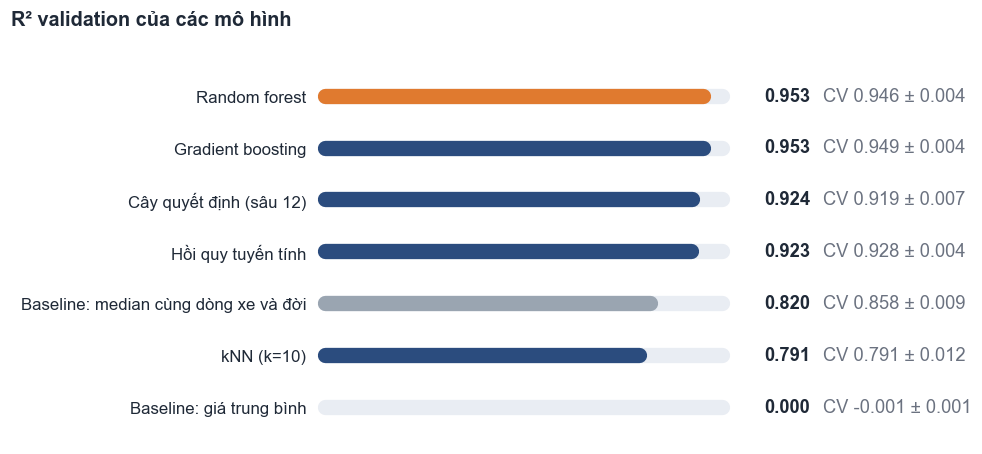

**Hình 16.** Số in đậm: R² validation; chữ xám: CV 5 fold trên train (trung bình ± độ lệch). Random forest và Gradient boosting cùng có R² validation 0.953, chênh nhau ít hơn độ lệch giữa các fold (0.004), nên được coi là ngang nhau; **Random forest** được chọn vì sai số % median thấp hơn (5.6% so với 6.0%). So với baseline median cùng dòng xe và đời, sai số % median giảm từ 6.6% xuống 5.6%.

Mô hình cuối cùng: Random forest


In [35]:
plot_res = val_res.sort_values("val_R2", ascending=False)
leader = plot_res.iloc[0]
tied = plot_res[plot_res["val_R2"] >= leader["val_R2"] - leader["cv_R2_std"]]
FINAL_NAME = tied.sort_values("val_median_APE_%").iloc[0]["model"]

fig, ax = plt.subplots(figsize=(9, 4.2))
colors = [ACCENT if n == FINAL_NAME else GREY if n.startswith("Baseline") else MAIN for n in plot_res["model"]]
hbars(ax, plot_res["model"], plot_res["val_R2"].clip(lower=0), colors=colors, xmax=1,
      notes=[(f"{round(r.val_R2, 3) + 0:.3f}", f"CV {round(r.cv_R2, 3) + 0:.3f} ± {r.cv_R2_std:.3f}")
             for r in plot_res.itertuples()])
ax.set(title="R² validation của các mô hình")

chosen = val_res.set_index("model").loc[FINAL_NAME]
base = val_res.set_index("model").loc["Baseline: median cùng dòng xe và đời"]
lo, hi = f"{tied['val_R2'].min():.3f}", f"{tied['val_R2'].max():.3f}"
r2_text = f"cùng có R² validation {hi}" if lo == hi else f"có R² validation từ {lo} đến {hi}"
tie_text = (f"{' và '.join(tied['model'])} {r2_text}, chênh nhau ít hơn độ lệch giữa các fold "
            f"({leader['cv_R2_std']:.3f}), nên được coi là ngang nhau; "
            f"**{FINAL_NAME}** được chọn vì sai số % median thấp hơn ({chosen['val_median_APE_%']:.1f}% so với "
            f"{tied.set_index('model').drop(FINAL_NAME)['val_median_APE_%'].min():.1f}%)."
            if len(tied) > 1 else f"**{FINAL_NAME}** có R² validation cao nhất ({chosen['val_R2']:.3f}).")
show_fig(fig, "model_comparison",
    f"Số in đậm: R² validation; chữ xám: CV 5 fold trên train (trung bình ± độ lệch). {tie_text} So với baseline median "
    f"cùng dòng xe và đời, sai số % median giảm từ {base['val_median_APE_%']:.1f}% xuống {chosen['val_median_APE_%']:.1f}%.")
print("Mô hình cuối cùng:", FINAL_NAME)

## 7. Đánh giá trên tập test

### 7.1 Kết quả trên test

Mọi mô hình đã huấn luyện trên train được chấm một lần trên test. Mô hình cuối cùng đã được chọn ở mục 6.6 theo
validation, không theo kết quả dưới đây.

In [36]:
test_res = pd.DataFrame([{"model": name, "final": name == FINAL_NAME, **scores(y["test"], m.predict(X["test"]))}
                         for name, m in FITTED.items()])
display(test_res.round(3))
final = FITTED[FINAL_NAME]
final_test = test_res.set_index("model").loc[FINAL_NAME]
final_val = val_res.set_index("model").loc[FINAL_NAME]
print(f"{FINAL_NAME}: R² CV {final_val['cv_R2']:.3f} | validation {final_val['val_R2']:.3f} | test {final_test['R2']:.3f}")

,model,final,R2,median_APE_%,within_10_%,MAE_trieu
0,Baseline: giá trung bình,False,-0.000,35.960,14.227,275.656
1,Baseline: median cùng dòng xe và đời,False,0.847,7.208,60.444,74.671
2,Hồi quy tuyến tính,False,0.932,7.914,58.717,72.406
3,kNN (k=10),False,0.812,14.595,36.842,122.583
4,Cây quyết định (sâu 12),False,0.917,7.999,56.908,72.615
5,Random forest,True,0.953,5.545,70.312,53.904
6,Gradient boosting,False,0.952,6.301,66.859,58.392


Random forest: R² CV 0.946 | validation 0.953 | test 0.953


- **Nhận xét:** random forest đạt R² **0.953** trên test, bằng validation (0.953) và gần cross-validation (0.946), nên
  kết quả ổn định giữa các tập. Một nửa số xe được đoán lệch không quá **5.5%** giá rao, so với 7.2% nếu chỉ tra giá
  median của xe cùng dòng và đời. Gradient boosting có R² test gần như bằng (0.952) nhưng sai số % median cao hơn
  (6.3%), nhất quán với kết luận "ngang nhau" ở mục 6.6. Thứ tự các mô hình trên test giống trên validation, chỉ có hồi
  quy tuyến tính và cây quyết định đổi chỗ cho nhau.

### 7.2 Dự đoán so với giá thật

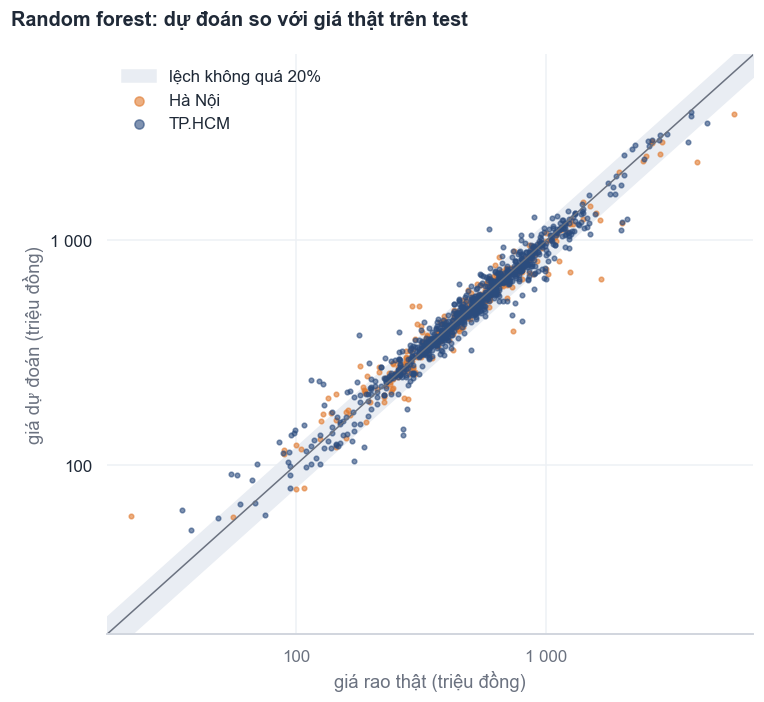

**Hình 17.** Trên 1 216 tin test, 89.1% tin được đoán lệch không quá 20% (dải xám) và một nửa số tin lệch không quá 5.5%. Chỉ 14 tin (1.2%) lệch quá 50%. Các điểm của Hà Nội và TP.HCM nằm lẫn vào nhau, không lệch về một phía.

In [37]:
res = FEAT["test"][["subject", "city", "brand_model", "mfg_year", "mileage_km", "seller_is_shop", TARGET]].copy()
res["pred"] = 10 ** final.predict(X["test"])
res["ape"] = (res["pred"] - res[TARGET]).abs() / res[TARGET]

fig, ax = plt.subplots(figsize=(7, 6.5))
lo, hi = res[[TARGET, "pred"]].min().min() * 0.8, res[[TARGET, "pred"]].max().max() * 1.2
grid = np.logspace(np.log10(lo), np.log10(hi), 50)
ax.fill_between(grid, grid * 0.8, grid * 1.2, color=TRACK, label="lệch không quá 20%")
ax.plot(grid, grid, color=MUTED, lw=1)
for city, g in res.groupby("city"):
    ax.scatter(g[TARGET], g["pred"], s=9, alpha=0.6, color=CITY_COLORS[city], label=city)
ax.set(xscale="log", yscale="log", xlim=(lo, hi), ylim=(lo, hi), xlabel="giá rao thật (triệu đồng)",
       ylabel="giá dự đoán (triệu đồng)", title=f"{FINAL_NAME}: dự đoán so với giá thật trên test")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(trieu))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(trieu))
ax.legend(markerscale=2)
within20 = (res["ape"] <= 0.2).mean()
far = res[res["ape"] > 0.5]
show_fig(fig, "pred_vs_true",
    f"Trên {num(len(res))} tin test, {pct(within20)} tin được đoán lệch không quá 20% (dải xám) và một nửa số tin lệch "
    f"không quá {100 * res['ape'].median():.1f}%. Chỉ {len(far)} tin ({pct(len(far) / len(res))}) lệch quá 50%. Các điểm "
    f"của Hà Nội và TP.HCM nằm lẫn vào nhau, không lệch về một phía.")

### 7.3 Mô hình dựa vào những feature nào?

Độ quan trọng được đo bằng **permutation importance** trên test: xáo trộn ngẫu nhiên một cột đầu vào (cột gốc, trước
tiền xử lý) rồi xem R² giảm bao nhiêu. Cột càng quan trọng thì R² giảm càng nhiều. Mỗi cột được xáo 5 lần.

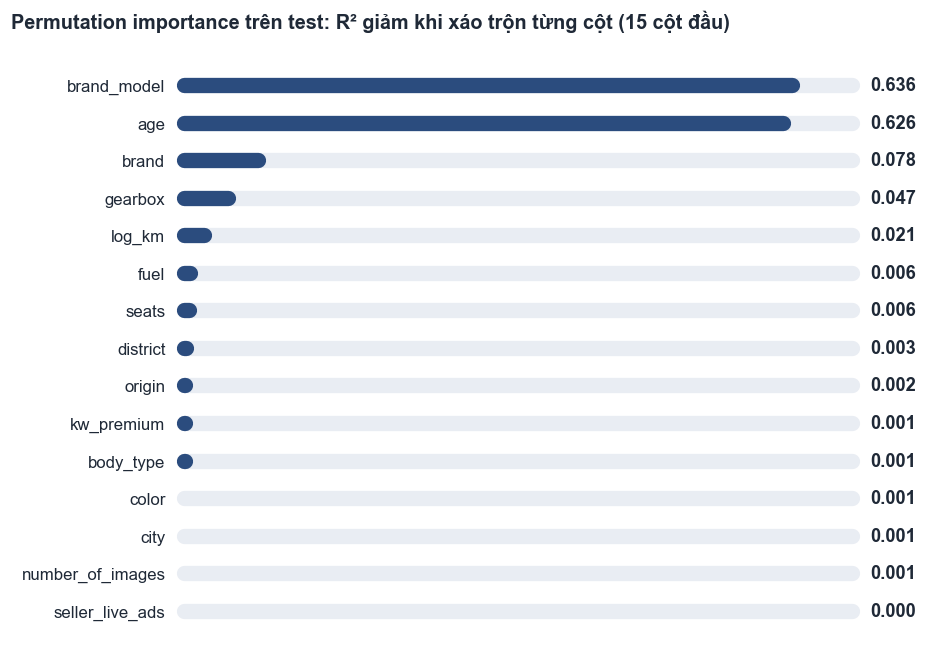

**Hình 18.** Hai cột quan trọng nhất là `brand_model` (R² giảm 0.636 khi bị xáo trộn) và `age` (0.626). `seats`, `body_type`, `origin` (các cột được điền theo dòng xe) lần lượt làm R² giảm 0.006, 0.001 và 0.002.

In [38]:
perm = permutation_importance(final, X["test"], y["test"], scoring="r2", n_repeats=5, random_state=SEED)
importance = pd.Series(perm.importances_mean, index=FEATURES).sort_values(ascending=False)
top = importance.head(15)

fig, ax = plt.subplots(figsize=(8.5, 6))
hbars(ax, top.index, top.clip(lower=0).values, xmax=top.max() * 1.1, notes=[(f"{v:.3f}", None) for v in top])
ax.set(title="Permutation importance trên test: R² giảm khi xáo trộn từng cột (15 cột đầu)")
show_fig(fig, "feature_importance",
    f"Hai cột quan trọng nhất là `{top.index[0]}` (R² giảm {top.iloc[0]:.3f} khi bị xáo trộn) và `{top.index[1]}` "
    f"({top.iloc[1]:.3f}). `seats`, `body_type`, `origin` (các cột được điền theo dòng xe) lần lượt làm R² giảm "
    f"{importance['seats']:.3f}, {importance['body_type']:.3f} và {importance['origin']:.3f}.")

### 7.4 Mô hình sai ở đâu?

Sai số % median theo 5 khoảng giá bằng nhau và theo nơi bán, người bán. Cột `pred/true` là median của tỉ số giá dự
đoán / giá thật: lớn hơn 1 nghĩa là mô hình thường đoán cao hơn giá rao.

In [39]:
res["price_band"] = pd.qcut(res[TARGET] / 1e6, 5).map(lambda b: f"{b.left:,.0f} - {b.right:,.0f} triệu".replace(",", " "))
res["seller"] = res["city"] + ", " + res["seller_is_shop"].map({1: "salon", 0: "cá nhân"})
res["ratio"] = res["pred"] / res[TARGET]


def error_table(by):
    return res.groupby(by, observed=True).agg(n=("ape", "size"), median_APE_pct=("ape", lambda s: 100 * s.median()),
                                              pred_over_true=("ratio", "median")).round(2)

display(error_table("price_band"))
display(error_table("seller"))
with pd.option_context("display.max_colwidth", 60):
    worst = res.sort_values("ape", ascending=False).head(5)
    display(worst[["subject", "mfg_year", "mileage_km", TARGET, "pred", "ape"]]
            .assign(**{TARGET: worst[TARGET] / 1e6, "pred": worst["pred"] / 1e6}).round(2))

,n,median_APE_pct,pred_over_true
price_band,,,
22 - 305 triệu,246,10.29,1.04
305 - 430 triệu,244,4.24,1.00
430 - 568 triệu,240,4.57,1.00
568 - 789 triệu,243,4.74,0.99
789 - 5 599 triệu,243,5.98,0.97


,n,median_APE_pct,pred_over_true
seller,,,
"Hà Nội, cá nhân",90,6.47,1.00
"Hà Nội, salon",246,5.48,1.01
"TP.HCM, cá nhân",216,6.68,0.99
"TP.HCM, salon",664,5.19,1.00


,subject,mfg_year,mileage_km,price_vnd,pred,ape
5559,Mitsubishi Jolie 8 chỗ Xăng Số sàn bạc,2002,NaN,22.00,59.28,1.69
498,Accent 2022.đưamifnh185tr ra góp tiếp NH.cho Thuê,2022,70572.0,179.00,377.43,1.11
1931,KIA Carnival 7 chỗ tự động màu Đen,2009,120000.0,115.00,239.58,1.08
3273,Hyundai SantaFe 2.0 EVTG fun dầu .hàn Quốc.,2009,256000.0,123.46,235.71,0.91
2292,LandRover Range Rover Evoque 2014 Dynamic 90000km,2014,90000.0,589.00,1123.93,0.91


- **Nhận xét:**
  - Sai số cao nhất ở 20% xe rẻ nhất (dưới 305 triệu): 10.3%, và mô hình thường đoán cao hơn giá rao (tỉ số 1.04).
    Đây là xe đời cũ, mỗi chiếc một tình trạng, và với xe vài trăm triệu thì chênh vài chục triệu đã là nhiều phần trăm.
    Ở 20% xe đắt nhất, mô hình hơi đoán thấp (0.97).
  - Tin của salon dễ đoán hơn tin của người bán cá nhân ở cả hai thành phố (5.2% và 5.5% so với 6.7% và 6.5%).
  - Năm tin sai nhiều nhất là xe cũ giá thấp hoặc tin có vấn đề về giá: một chiếc Mitsubishi Jolie 2002 rao 22 triệu,
    một tin Hyundai Accent ghi "đưa mình 185tr ra góp tiếp" (giá là phần tiền góp còn lại, không phải giá xe), một chiếc
    Range Rover Evoque 2014 rao 589 triệu trong khi mô hình đoán 1 124 triệu.

### 7.5 Lưu bảng kết quả

In [40]:
table = test_res.assign(model=test_res["model"] + np.where(test_res["final"], " (cuối cùng)", ""))
table = table.drop(columns="final").rename(columns={"R2": "R² test", "median_APE_%": "Sai số % median",
                                                    "within_10_%": "Lệch ≤ 10%", "MAE_trieu": "MAE (triệu)"})
table = table.round(3)
table.to_csv(RESULTS_DIR / "tabular_metrics.csv", index=False)
lines = ["| " + " | ".join(table.columns) + " |", "|" + "---|" * len(table.columns)]
lines += ["| " + " | ".join(str(v) for v in r) + " |" for r in table.itertuples(index=False)]
(RESULTS_DIR / "tabular_metrics.md").write_text("\n".join(lines) + "\n", encoding="utf-8")
table

,model,R² test,Sai số % median,Lệch ≤ 10%,MAE (triệu)
0,Baseline: giá trung bình,-0.000,35.960,14.227,275.656
1,Baseline: median cùng dòng xe và đời,0.847,7.208,60.444,74.671
2,Hồi quy tuyến tính,0.932,7.914,58.717,72.406
3,kNN (k=10),0.812,14.595,36.842,122.583
4,Cây quyết định (sâu 12),0.917,7.999,56.908,72.615
5,Random forest (cuối cùng),0.953,5.545,70.312,53.904
6,Gradient boosting,0.952,6.301,66.859,58.392


## 8. Dự đoán giá một chiếc xe

### 8.1 Hàm dự đoán từ thông tin một chiếc xe

`predict_price()` nhận thông tin như khi đăng một tin trên Chợ Tốt, đi qua đúng các bước tạo feature và pipeline của
mô hình cuối cùng. Cột nào không khai thì pipeline tự điền như với dữ liệu train. Dòng xe ngoài phạm vi của mô hình bị
từ chối thay vì trả về một con số không đáng tin.

In [41]:
KNOWN_MODELS = set(FEAT["train"]["brand_model"])


def predict_price(**car):
    row = pd.DataFrame([car])
    row["brand_model"] = row["brand"] + " | " + row["model"]
    if row["brand_model"].iloc[0] not in KNOWN_MODELS:
        raise ValueError(f"{row['brand_model'].iloc[0]} nằm ngoài {len(KNOWN_MODELS)} dòng xe mô hình đã học")
    defaults = {"subject": "", "mileage_km": np.nan, "seller_is_shop": False, "number_of_images": 8}
    for col, value in defaults.items():
        if col not in row:
            row[col] = value
    row = add_features(row).reindex(columns=FEATURES)
    return float(10 ** final.predict(row)[0])

### 8.2 Thử với một chiếc xe

Bắt đầu từ một chiếc Toyota Innova 2019, đi 80 000 km, bán ở TP.HCM, rồi thay đổi từng thông tin một.

In [42]:
base_car = dict(brand="Toyota", model="Innova", mfg_year=2019, mileage_km=80_000, city="TP.HCM", district="Quận Gò Vấp",
                fuel="Xăng", gearbox="Số sàn", seats=8, body_type="Minivan (MPV)", origin="Việt Nam", seller_is_shop=False)
changes = {
    "Xe gốc": {},
    "Đời 2015 thay vì 2019": {"mfg_year": 2015},
    "Đi 150 000 km thay vì 80 000 km": {"mileage_km": 150_000},
    "Bán ở Hà Nội (Cầu Giấy)": {"city": "Hà Nội", "district": "Quận Cầu Giấy"},
    "Do salon bán": {"seller_is_shop": True},
    "Không khai số ghế, kiểu dáng, xuất xứ": {"seats": np.nan, "body_type": np.nan, "origin": np.nan},
    "Toyota Fortuner thay vì Innova": {"model": "Fortuner", "seats": 7, "body_type": "SUV / Cross over"},
}
examples = pd.Series({k: predict_price(**{**base_car, **v}) / 1e6 for k, v in changes.items()}, name="giá dự đoán (triệu)")
examples.round(1).to_frame()

,giá dự đoán (triệu)
Xe gốc,373.2
Đời 2015 thay vì 2019,252.0
Đi 150 000 km thay vì 80 000 km,375.9
Bán ở Hà Nội (Cầu Giấy),367.8
Do salon bán,375.9
"Không khai số ghế, kiểu dáng, xuất xứ",373.0
Toyota Fortuner thay vì Innova,561.3


- Chiếc Innova 2019 gốc được đoán 373 triệu. Lùi đời về 2015 làm giá còn 252 triệu (giảm 32%, khoảng 9% mỗi năm, khớp
  với Hình 8).
- Tăng số km từ 80 000 lên 150 000 gần như không đổi giá (376 triệu): như Hình 9, khi đã biết đời xe thì số km chỉ làm
  giá chênh vài phần trăm. Bán ở Hà Nội hay do salon bán cũng chỉ chênh khoảng 1%.
- Bỏ trống số ghế, kiểu dáng và xuất xứ cho kết quả gần như y hệt (373 triệu), vì pipeline điền lại đúng các giá trị
  phổ biến của Innova.
- Đổi sang Fortuner cùng đời thì giá lên 561 triệu: dòng xe vẫn là yếu tố quyết định.

## 9. Kết luận

### 9.1 Tóm tắt kết quả trên tập test

| Mô hình | R² (log giá) | Sai số % median | Lệch ≤ 10% | MAE (triệu) |
|---|---|---|---|---|
| Baseline: giá trung bình | 0.000 | 36.0% | 14.2% | 275.7 |
| Baseline: median cùng dòng xe và đời | 0.847 | 7.2% | 60.4% | 74.7 |
| Hồi quy tuyến tính | 0.932 | 7.9% | 58.7% | 72.4 |
| kNN (k = 10) | 0.812 | 14.6% | 36.8% | 122.6 |
| Cây quyết định (sâu 12) | 0.917 | 8.0% | 56.9% | 72.6 |
| **Random forest (mô hình cuối cùng)** | **0.953** | **5.5%** | **70.3%** | **53.9** |
| Gradient boosting | 0.952 | 6.3% | 66.9% | 58.4 |

Trên 85 dòng xe phổ biến (78% số tin xe đã dùng sau khi làm sạch), random forest giải thích 95.3% biến động của log giá
trên tập test và đoán một nửa số xe lệch không quá 5.5% giá rao.

### 9.2 Các câu hỏi đã được trả lời

| # | Câu hỏi | Trả lời |
|---|---|---|
| 1 | Tin rao thiếu những gì, vì sao? | Ba kiểu thiếu: không áp dụng (xe mới không có số km, giấy tờ), thiếu ẩn (số ghế `Khác`, số km ảo), người bán bỏ trống (`origin` 39%, các cột giấy tờ 44 - 50%, `body_type` 25%). Việc thiếu phụ thuộc vào người bán, không liên quan tới giá (mục 3.1 - 3.3). |
| 2 | Điền thế nào để có cơ sở? | Điền theo dòng xe đúng 90 - 91% với kiểu dáng và số ghế, 67% với xuất xứ, so với 42 - 53% khi điền một giá trị chung; màu và giấy tờ không suy ra được nên để nhóm `không rõ`. Trên các tin có ô thiếu, sai số là 5.8%, so với 6.3% khi điền đơn giản và 7.6% khi bỏ tin thiếu khỏi train (mục 5.3, 6.5). |
| 3 | Mỗi năm xe mất bao nhiêu giá, hãng nào giữ giá? | Trung bình 8.9% mỗi năm khi so trong cùng dòng xe; Mazda giữ giá tốt nhất (6.3%), Mercedes Benz mất nhanh nhất (13.2%), Toyota ở giữa (8.3%) (mục 4.3). |
| 4 | Số km, thành phố, xuất xứ ảnh hưởng đến đâu? | Khi cùng dòng xe và cùng đời, chỉ vài phần trăm: xe chạy dưới 5 000 km/năm rao 1.02 lần, trên 30 000 km/năm 0.98 lần giá median; Hà Nội / TP.HCM 0.993; nhập khẩu / lắp ráp 0.995 (mục 4.4, 4.5). |
| 5 | Mô hình nào tốt nhất? | Random forest và gradient boosting ngang nhau về R²; random forest được chọn vì sai số thấp hơn, giảm sai số % median từ 7.2% (baseline) xuống 5.5% trên test (mục 6.6, 7.1). |
| 6 | Mô hình sai ở đâu? | Ở xe rẻ dưới 305 triệu (sai số 10.3%), tin của người bán cá nhân, và các tin mà giá không phải giá xe (mục 7.4). |

### 9.3 Hạn chế

* **Giá rao không phải giá bán.** Nhãn là giá người bán tự đặt; dữ liệu không cho biết xe được bán với giá bao nhiêu.
* **Một lần thu thập.** Dữ liệu là các tin đang hiển thị chiều 20/11/2026. Xe bán nhanh có thể đã bị gỡ trước đó, và mô
  hình chưa biết giá thay đổi theo thời gian.
* **Thiếu thông tin tình trạng xe.** Đâm đụng, ngập nước, lịch sử bảo dưỡng nằm trong phần mô tả và ảnh mà nhóm không thu
  thập để bảo vệ thông tin cá nhân. Phiên bản xe chỉ được nhận ra qua vài từ khóa trong tiêu đề.
* **Một nửa số tin không có thông tin giấy tờ** (số đời chủ, đăng kiểm), nên mô hình gần như không học được ảnh hưởng
  của các yếu tố này.
* **Chỉ áp dụng cho 85 dòng xe phổ biến.** Dòng hiếm và các nhóm `Dòng khác` nằm ngoài phạm vi.
* **Luật bỏ giá vô lý dùng nhãn.** Mục 5.1 bỏ 12 tin ở validation và test dựa trên chính giá rao của chúng, nên điểm chỉ
  áp dụng cho các tin có giá hợp lý.
* **Năm sản xuất do người bán khai** và không kiểm chứng được; 1.3% tiêu đề ghi năm lệch hơn 1 năm so với cột này.
* **Tinh chỉnh ít.** Mỗi mô hình chỉ thử vài giá trị tham số, chọn theo validation.

### 9.4 Hướng mở rộng

* Thu thập định kỳ để theo dõi giá theo thời gian và ước lượng tốc độ bán của từng dòng xe.
* Lấy phiên bản xe có cấu trúc từ trang chi tiết của tin, thay cho từ khóa trong tiêu đề.
* Trích tình trạng xe (đâm đụng, ngập nước, bảo dưỡng hãng) từ phần mô tả sau khi ẩn danh.
* Dự đoán một khoảng giá (quantile regression) thay vì một con số, để người mua biết mức giá nào là bất thường.